# [11.5] Contrast-Consistent Search

# Introduction

You have a frozen language model and a collection of questions. You can inspect
its activations, but you do not give your fitting algorithm the correct answers.
Could it discover a useful way to separate the answers anyway?

Consider two prompts: `Was the film enjoyable? Answer: Yes` and
`Was the film enjoyable? Answer: No`. A reporter assigning a score to each
statement should give opposite answers to the pair. It should also make a
decision instead of assigning both statements a score of one half. These two
requirements define a short optimization problem called **Contrast-Consistent
Search (CCS)**. You will implement it, see it find a feature, and then make an
independent feature satisfy exactly the same requirements.

The aim is to distinguish finding structure from identifying what that structure
means. Keep three questions in mind: **what did the algorithm fit, which way
does its score point, and what evidence identifies the feature?**

## Content & Learning Objectives

### 1️⃣ Build a contrast pair

> - Track answer-token offsets separately from variation between questions.
> - Fit centering on training data and apply it unchanged to new data.

### 2️⃣ Learn a reporter without fitting labels

> - Implement both terms of the original CCS objective.
> - Connect its scalar loss to visible probabilities and failure cases.
> - Fit independent restarts and select using their unlabelled training loss.

### 3️⃣ Find out what was learned

> - Construct a target and an unrelated distractor with equally good solutions.
> - Separate numerical sign conventions from labelled semantic orientation.
> - Compare CCS with a paired-difference principal component and random directions.

### 4️⃣ Trace competing opinions inside a real model

> - Extract correctly aligned candidate-answer activations.
> - Retain every fit and keep calibration separate from final evaluation.
> - Compare controlled opinion changes with actual native outputs.

## Setup

This lesson runs on CPU. Allow roughly two hours for the foundations and
another two hours to implement and investigate the native study. The full
model experiment takes a few minutes once the exercises are complete.
Complete each function before running its tests. Use the help and solution
dropdowns when useful, and predict the next plot before displaying it.


In [1]:
import itertools
import json
import math
import os
import sys
from collections.abc import Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import Tensor
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapter11_representation_geometry").exists())
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))
from chapter11_representation_geometry.exercises.part5_contrast_consistent_search import ccs_methods_tests as tests
assets_dir = Path(os.environ.get("ARENA_CCS_OUTPUT_DIRECTORY", "ccs_outputs"))
assets_dir.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
plt.style.use("seaborn-v0_8-whitegrid")

def save_figure(figure, name):
    figure.savefig(assets_dir / name, dpi=160, bbox_inches="tight")
    plt.show()

def _check_pairs(plus: Tensor, minus: Tensor) -> None:
    if plus.ndim != 2 or plus.shape != minus.shape or min(plus.shape) == 0:
        raise ValueError("Paired activations must have matching nonempty (examples, features) shapes.")
    if plus.dtype != minus.dtype or plus.device != minus.device:
        raise ValueError("Both branches must have the same dtype and device.")
    if not plus.is_floating_point() or not torch.isfinite(plus).all() or not torch.isfinite(minus).all():
        raise ValueError("Activations must be finite floating-point tensors.")

def _check_scores_labels(scores: Tensor, labels: Tensor) -> None:
    if scores.ndim != 1 or scores.shape != labels.shape or len(scores) == 0:
        raise ValueError("Provide equally sized nonempty score and label vectors.")
    if not torch.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Scores must lie in [0, 1].")
    if ((labels != 0) & (labels != 1)).any():
        raise ValueError("Labels must be binary.")


# 1️⃣ What makes the two activations different?

## A representation whose coordinates we understand

Let $Y$ be the answer we care about and $S$ an independent distractor. Each takes
values $-1$ or $+1$. Let $U$ be content shared by both members of a pair. Use
every combination of $(Y,S,U)$ equally often, and construct

$$x^+=(8,Y,3S,U),\qquad x^-=(-8,-Y,-3S,U).$$

The first coordinate only identifies the proposed answer. It is always positive
for the plus branch, regardless of whether that answer is correct. The second
coordinate is a useful target feature. The third tracks a distractor, and the
fourth does not reverse across the pair. We deliberately put both a useful and
a misleading answer-dependent feature into this representation. This makes
their availability explicit; it does not assume every language model has them.

Before fitting anything, write down the mean of each branch. A single pooled
mean is zero and removes neither answer offset. Separate means remove that
offset while retaining variation between questions. We will use mean-only
centering, matching the default of the original demonstration code.


In [2]:
target_sign, distractor_sign, content = torch.tensor(
    list(itertools.product((-1.0, 1.0), repeat=3)), dtype=torch.float64
).T
plus_raw = torch.stack((torch.full_like(target_sign, 8), target_sign, 3 * distractor_sign, content), dim=-1)
minus_raw = torch.stack((torch.full_like(target_sign, -8), -target_sign, -3 * distractor_sign, content), dim=-1)
target_labels = (target_sign > 0).long()
distractor_labels = (distractor_sign > 0).long()
print("Each branch:", tuple(plus_raw.shape), "— examples × features")
print("Plus mean:", plus_raw.mean(0).tolist())
print("Minus mean:", minus_raw.mean(0).tolist())


Each branch: (8, 4) — examples × features
Plus mean: [8.0, 0.0, 0.0, 0.0]
Minus mean: [-8.0, 0.0, 0.0, 0.0]


### Exercise 1 — Fit and apply branch centering

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Return the two training means, each with shape `[features]`. Then apply
those fitted means to both branches of any split. Do not modify the original
activations. In particular, the application function must not estimate a new
mean from the data passed to it.

<details>
<summary>Help</summary>

Use `.mean(0)` separately. Test-time centering would answer a different, transductive question: it uses the unlabelled evaluation distribution.

</details>

<details>
<summary>Expected output</summary>

Training means after centering are zero. The held-out shift in the test remains visible instead of being silently removed.

</details>

<details>
<summary>Solution</summary>

```python
def fit_pair_centering(plus: Tensor, minus: Tensor) -> dict[str, Tensor]:
    """Fit separate branch means on training data; there is no scale normalization."""
    _check_pairs(plus, minus)
    return {"plus_mean": plus.detach().mean(0), "minus_mean": minus.detach().mean(0)}
def apply_pair_centering(
    plus: Tensor, minus: Tensor, centering: dict[str, Tensor]
) -> tuple[Tensor, Tensor]:
    """Apply fitted means to any split, without refitting on that split."""
    _check_pairs(plus, minus)
    if any(centering[key].shape != (plus.shape[1],) for key in ("plus_mean", "minus_mean")):
        raise ValueError("A training mean must have one value per feature.")
    return plus - centering["plus_mean"], minus - centering["minus_mean"]
```

</details>


In [ ]:
def fit_pair_centering(plus: Tensor, minus: Tensor) -> dict[str, Tensor]:
    """Fit separate branch means on training data; there is no scale normalization."""
    raise NotImplementedError()

def apply_pair_centering(plus: Tensor, minus: Tensor, centering: dict[str, Tensor]) -> tuple[Tensor, Tensor]:
    """Apply fitted means to any split, without refitting on that split."""
    raise NotImplementedError()

tests.test_pair_centering(fit_pair_centering, apply_pair_centering)
print("Training centering and held-out shift checks passed!")


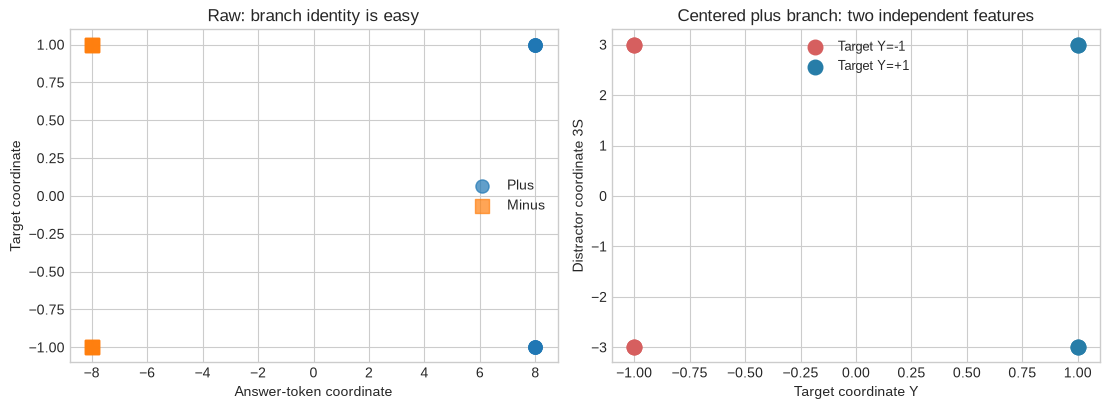

In [4]:
centering = fit_pair_centering(plus_raw, minus_raw)
plus, minus = apply_pair_centering(plus_raw, minus_raw, centering)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
for branch, matrix, marker in [("Plus", plus_raw, "o"), ("Minus", minus_raw, "s")]:
    axes[0].scatter(matrix[:, 0], matrix[:, 1], marker=marker, s=90, alpha=.7, label=branch)
axes[0].set(xlabel="Answer-token coordinate", ylabel="Target coordinate", title="Raw: branch identity is easy")
axes[0].legend()
for label, color in [(0, "#d65f5f"), (1, "#277da8")]:
    use = target_labels == label
    axes[1].scatter(plus[use, 1], plus[use, 2], s=110, c=color, label=f"Target Y={2 * label - 1:+}")
axes[1].set(xlabel="Target coordinate Y", ylabel="Distractor coordinate 3S", title="Centered plus branch: two independent features")
axes[1].legend(loc="upper center", fontsize=9)
fig.tight_layout()
save_figure(fig, "ccs_contrast_geometry.png")


<details>
<summary>Interpretation — why do only four points appear on the right?</summary>

The two values of $U$ overlap when we display only the target and distractor
coordinates. No examples were dropped. The distractor is exactly balanced within
each target class. A vertical boundary reads $Y$; a horizontal boundary reads
$S$. Both features will reverse between the plus and minus branches.

</details>

# 2️⃣ Turn consistency into an objective

For each branch, an affine reporter produces
$p^\pm=\sigma(w^\top x^\pm+b)$. Here $p^+$ is a score for the plus statement,
not yet a reliably oriented probability that the question's correct answer is
plus. Define the original loss for one pair as

$$L_\mathrm{cons}=(p^++p^--1)^2,\qquad
L_\mathrm{conf}=\min(p^+,p^-)^2.$$

Average their sum over questions. At $(p^+,p^-)=(1/2,1/2)$, consistency alone is
perfect but neither statement has been selected. At $(0,0)$, confidence alone
is perfect but the two statements are both rejected. The combined objective
prefers opposite, confident predictions. It has no term referring to $Y$.

These equations are from [Burns et al.'s CCS method](https://arxiv.org/html/2212.03827v2).
The reporter parameters change; the representation that supplies its input does
not. In a transformer study this means freezing the pretrained model.


### Exercise 2 — Compute both CCS losses

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Implement the loss for probabilities shaped `[examples]`, or
`[examples, restarts]` when fitting independent reporters together. Average over
examples only. Return `(total, consistency, confidence)`. Reject shape mismatch
instead of allowing broadcasting to compare every plus example with every minus
example.

<details>
<summary>Help</summary>

Use `torch.minimum` before squaring. Averaging over restarts here would rescale the independent optimization problems.

</details>

<details>
<summary>Expected output</summary>

Opposite confident pairs have loss 0; two half scores give .25; two zero scores give 1. The independent analytic-gradient check also passes.

</details>

<details>
<summary>Solution</summary>

```python
def ccs_loss(p_plus: Tensor, p_minus: Tensor) -> tuple[Tensor, Tensor, Tensor]:
    """Original loss, consistency and confidence, averaged over examples only.

    Inputs are (examples,) or (examples, independent_reporters). Returning one
    loss per reporter makes batching equivalent to fitting each independently.
    """
    if p_plus.ndim not in (1, 2) or p_plus.shape != p_minus.shape or p_plus.shape[0] == 0:
        raise ValueError("Probabilities must have matching nonempty shapes; broadcasting is forbidden.")
    if any(not torch.isfinite(p).all() or ((p < 0) | (p > 1)).any() for p in (p_plus, p_minus)):
        raise ValueError("Probabilities must be finite and lie in [0, 1].")
    consistency = (p_plus + p_minus - 1).square().mean(0)
    confidence = torch.minimum(p_plus, p_minus).square().mean(0)
    return consistency + confidence, consistency, confidence
```

</details>


In [ ]:
def ccs_loss(p_plus: Tensor, p_minus: Tensor) -> tuple[Tensor, Tensor, Tensor]:
    """Original loss, consistency and confidence, averaged over examples only.

    Inputs are (examples,) or (examples, independent_reporters). Returning one
    loss per reporter makes batching equivalent to fitting each independently.
    """
    raise NotImplementedError()

tests.test_ccs_loss_values(ccs_loss)
tests.test_ccs_loss_gradient(ccs_loss)
print("Exact loss values and independent gradient checks passed!")


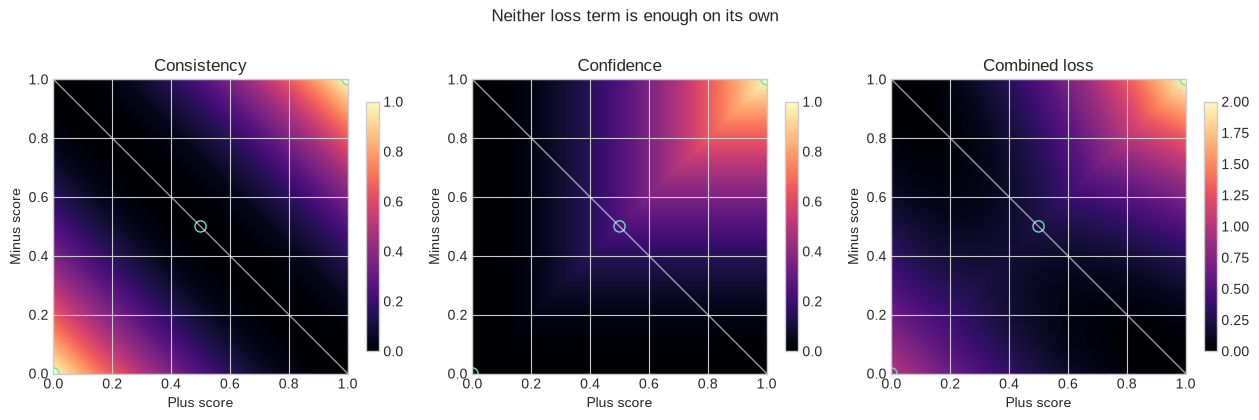

In [6]:
grid = torch.linspace(0, 1, 181, dtype=torch.float64)
pp, pm = torch.meshgrid(grid, grid, indexing="xy")
total, consistency, confidence = ccs_loss(pp.reshape(1, -1), pm.reshape(1, -1))
fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.8))
for ax, values, title in zip(axes, [consistency, confidence, total], ["Consistency", "Confidence", "Combined loss"]):
    heat = ax.imshow(values.reshape(181, 181), origin="lower", extent=[0, 1, 0, 1], cmap="magma", aspect="equal")
    ax.plot([0, 1], [1, 0], color="white", linewidth=1, alpha=.6)
    ax.scatter([0, .5, 1], [0, .5, 1], facecolors="none", edgecolors="#5be7c4", s=65)
    ax.set(xlabel="Plus score", ylabel="Minus score", title=title)
    fig.colorbar(heat, ax=ax, shrink=.8)
fig.suptitle("Neither loss term is enough on its own", y=1.04)
fig.tight_layout()
save_figure(fig, "ccs_loss_landscape.png")


<details>
<summary>Interpretation — is the loss unchanged if we flip every score?</summary>

Not for arbitrary soft scores. $(.8,.6)$ gives $.52$, while $(.2,.4)$ gives
$.20$. The confidence term prefers smaller scores when consistency is imperfect.
On the exact consistency line $p^++p^-=1$, however, the two orientations have
equal loss. Neither of its two confident endpoints has a preferred semantic
meaning. Do not turn this ambiguity into an incorrect global symmetry claim.

Another useful check: the best constant equal score is $.4$, with total loss
$.2$. Differentiate $(2p-1)^2+p^2$ to verify it. Lowish loss alone does not show
that a reporter has learned different answers for different questions.

</details>


### Exercise 3 — Combine the two statement scores

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Compute $\tilde p=\tfrac12(p^++1-p^-)$, returning it along with the
two branch probabilities. Support a single weight vector and a matrix whose
rows are independent reporters. This averaging makes disagreement between the
branches visible rather than replacing one by the other's complement.

<details>
<summary>Help</summary>

For many reporters, `plus @ weight.T` has shape `[examples, reporters]`. Adding the corresponding bias vector broadcasts only over examples.

</details>

<details>
<summary>Expected output</summary>

Swapping the branches complements the averaged score. Negating the affine parameters also complements it, even though the original soft loss need not stay equal.

</details>

<details>
<summary>Solution</summary>

```python
def paired_probabilities(
    plus: Tensor, minus: Tensor, weight: Tensor, bias: Tensor
) -> tuple[Tensor, Tensor, Tensor]:
    """Return averaged positive-answer scores and the two branch probabilities.

    A vector weight gives one reporter; (reporters, features) gives many.
    A score is not semantically oriented until a separate orientation is chosen.
    """
    _check_pairs(plus, minus)
    if weight.ndim not in (1, 2) or weight.shape[-1] != plus.shape[-1]:
        raise ValueError("Reporter weights must end in the activation feature dimension.")
    expected_bias = () if weight.ndim == 1 else (weight.shape[0],)
    if bias.shape != expected_bias:
        raise ValueError("Bias must be scalar for one reporter or one value per reporter.")
    p_plus = (plus @ weight.T + bias).sigmoid() if weight.ndim == 2 else (plus @ weight + bias).sigmoid()
    p_minus = (minus @ weight.T + bias).sigmoid() if weight.ndim == 2 else (minus @ weight + bias).sigmoid()
    return (p_plus + 1 - p_minus) / 2, p_plus, p_minus
```

</details>


In [ ]:
def paired_probabilities(plus: Tensor, minus: Tensor, weight: Tensor, bias: Tensor) -> tuple[Tensor, Tensor, Tensor]:
    """Return averaged positive-answer scores and the two branch probabilities.

    A vector weight gives one reporter; (reporters, features) gives many.
    A score is not semantically oriented until a separate orientation is chosen.
    """
    raise NotImplementedError()

tests.test_paired_inference(paired_probabilities)
tests.test_two_feature_counterexample(paired_probabilities, ccs_loss)
print("Paired inference and independent-feature counterexample passed!")


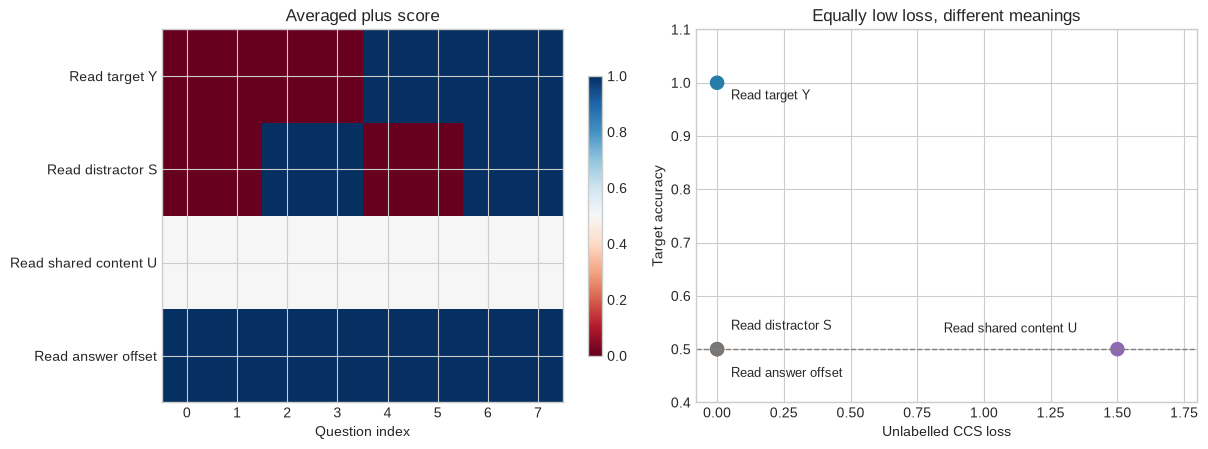

In [8]:
known_reporters = {
    "Read target Y": torch.tensor([0., 15., 0., 0.], dtype=plus.dtype),
    "Read distractor S": torch.tensor([0., 0., 5., 0.], dtype=plus.dtype),
    "Read shared content U": torch.tensor([0., 0., 0., 15.], dtype=plus.dtype),
    "Read answer offset": torch.tensor([2., 0., 0., 0.], dtype=plus.dtype),
}
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))
rows, names, losses, accuracies = [], [], [], []
for name, weight in known_reporters.items():
    xp, xm = (plus_raw, minus_raw) if name == "Read answer offset" else (plus, minus)
    score, p, m = paired_probabilities(xp, xm, weight, torch.tensor(0., dtype=plus.dtype))
    rows.append(score.numpy()); names.append(name)
    losses.append(float(ccs_loss(p, m)[0]))
    accuracies.append(float(((score > .5) == target_labels).double().mean()))
heat = axes[0].imshow(np.array(rows), vmin=0, vmax=1, cmap="RdBu", aspect="auto")
axes[0].set(yticks=range(4), yticklabels=names, xticks=range(8), xlabel="Question index", title="Averaged plus score")
fig.colorbar(heat, ax=axes[0], shrink=.75)
axes[1].scatter(losses, accuracies, s=90, c=["#277da8", "#e08b35", "#8e69b3", "#777777"])
for name, loss, accuracy in zip(names, losses, accuracies):
    offset = {"Read target Y": (10, -12), "Read distractor S": (10, 14), "Read shared content U": (-125, 12), "Read answer offset": (10, -20)}[name]
    axes[1].annotate(name, (loss, accuracy), xytext=offset, textcoords="offset points", fontsize=9)
axes[1].axhline(.5, color="gray", linestyle="--", linewidth=1)
axes[1].set(xlabel="Unlabelled CCS loss", ylabel="Target accuracy", ylim=(.4, 1.1), title="Equally low loss, different meanings")
axes[1].set_xlim(-.08, 1.8)
fig.tight_layout()
save_figure(fig, "ccs_exact_counterexample.png")


<details>
<summary>Interpretation — which failure did centering fix?</summary>

Centering removes the constant answer-token coordinate. Without it, the answer
offset reporter gives every question the same averaged answer while satisfying
the pairwise loss almost perfectly. With it, that reporter produces only halves.
It does not remove the independent distractor: $S$ varies across questions and
reverses across the two branches, just as $Y$ does.

The target and distractor scores have equally small positive loss because a
finite sigmoid cannot reach 0 or 1 exactly. The plotted target accuracy is 100%
versus 50%. The same loss is therefore compatible with a useful classifier and
an irrelevant one in this explicitly linear representation.

</details>

# 3️⃣ Fit the reporter and inspect every restart

Now let optimization find a direction. We will use ten independent initializations,
1000 AdamW steps, learning rate $.01$ and weight decay $.01$. There is no label
argument. Each restart has its own parameters and optimizer state; running their
matrix operations together only reduces repeated overhead.

Do not pick the seed with the best target accuracy. Our selection rule is the
lowest **final training CCS loss**, with the first restart breaking a tie. Keep
the whole history, including the loss recomputed after the last update. AdamW
weight decay acts on the parameters; it is not included in the plotted CCS loss.


### Exercise 4 — Fit independent restarts and select without labels

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 25–35 minutes on this exercise.
> ```

Return every restart's weights, biases and a `[steps + 1, restarts, 3]`
history containing total, consistency and confidence losses. Use local random
generators so fitting does not reset unrelated notebook randomness. Optimize
the sum of the separate reporters' losses. Then implement the stated selection
rule using only this history.

<details>
<summary>Help</summary>

Initialize each weight vector and bias uniformly between
`-1 / sqrt(width)` and `1 / sqrt(width)`, using its own seed. A single AdamW
optimizer can hold the stacked parameter tensors because its moment estimates
are elementwise. Recompute the final loss before selecting.

</details>

<details>
<summary>Expected output</summary>

Batched fits match separate single-seed fits to numerical precision,
including their histories. Inputs and global random state stay unchanged. The
selection test deliberately contains tied losses.

</details>

<details>
<summary>Solution</summary>

```python
def fit_ccs_restarts(
    plus: Tensor,
    minus: Tensor,
    *,
    seeds: Sequence[int] = tuple(range(10)),
    steps: int = 1000,
    learning_rate: float = 0.01,
    weight_decay: float = 0.01,
) -> dict[str, Tensor | list[int]]:
    """Fit independent affine reporters with AdamW and retain every restart.

    Inputs must already have training-fitted centering applied. Independent
    parameter rows are optimized together; sum, rather than mean, over their
    losses preserves each reporter's gradient. The final loss is recomputed
    after the final update. No labels or validation scores enter this function.
    """
    _check_pairs(plus, minus)
    seeds = list(seeds)
    if not seeds or len(set(seeds)) != len(seeds):
        raise ValueError("Provide at least one unique restart seed.")
    if steps < 1 or learning_rate <= 0 or weight_decay < 0:
        raise ValueError("Steps and learning rate must be positive; weight decay must be nonnegative.")
    plus, minus = plus.detach(), minus.detach()
    width = plus.shape[1]
    bound = 1 / math.sqrt(width)
    initial_weights, initial_biases = [], []
    for seed in seeds:
        generator = torch.Generator(device=plus.device).manual_seed(seed)
        initial_weights.append(
            torch.empty(width, dtype=plus.dtype, device=plus.device).uniform_(-bound, bound, generator=generator)
        )
        initial_biases.append(
            torch.empty((), dtype=plus.dtype, device=plus.device).uniform_(-bound, bound, generator=generator)
        )
    weight = torch.stack(initial_weights).requires_grad_()
    bias = torch.stack(initial_biases).requires_grad_()
    optimizer = torch.optim.AdamW([weight, bias], lr=learning_rate, weight_decay=weight_decay)
    history = []
    for step in range(steps + 1):
        _, p_plus, p_minus = paired_probabilities(plus, minus, weight, bias)
        loss, consistency, confidence = ccs_loss(p_plus, p_minus)
        history.append(torch.stack((loss, consistency, confidence), dim=-1).detach().cpu())
        if step == steps:
            break
        optimizer.zero_grad(set_to_none=True)
        loss.sum().backward()
        optimizer.step()
    return {
        "weights": weight.detach().clone(),
        "biases": bias.detach().clone(),
        "history": torch.stack(history),
        "seeds": seeds,
    }
def select_restart(fitted: dict) -> dict:
    """Choose the first minimum final training-loss restart, without labels."""
    history = fitted["history"]
    if history.ndim != 3 or history.shape[-1] != 3 or not torch.isfinite(history).all():
        raise ValueError("Expected finite (steps + 1, restarts, 3) loss history.")
    count = len(fitted["seeds"])
    if history.shape[1] != count or fitted["weights"].shape[0] != count or fitted["biases"].shape != (count,):
        raise ValueError("Restart parameters, seeds and history must agree.")
    index = int(history[-1, :, 0].argmin())
    return {
        "index": index,
        "seed": fitted["seeds"][index],
        "weight": fitted["weights"][index].clone(),
        "bias": fitted["biases"][index].clone(),
        "training_loss": float(history[-1, index, 0]),
    }
```

</details>


In [ ]:
def fit_ccs_restarts(plus: Tensor, minus: Tensor, *, seeds: Sequence[int]=tuple(range(10)), steps: int=1000, learning_rate: float=0.01, weight_decay: float=0.01) -> dict[str, Tensor | list[int]]:
    """Fit independent affine reporters with AdamW and retain every restart.

    Inputs must already have training-fitted centering applied. Independent
    parameter rows are optimized together; sum, rather than mean, over their
    losses preserves each reporter's gradient. The final loss is recomputed
    after the final update. No labels or validation scores enter this function.
    """
    raise NotImplementedError()

def select_restart(fitted: dict) -> dict:
    """Choose the first minimum final training-loss restart, without labels."""
    raise NotImplementedError()

tests.test_batched_restarts(fit_ccs_restarts)
tests.test_restart_selection(select_restart)
print("Independent restart equivalence and selection checks passed!")


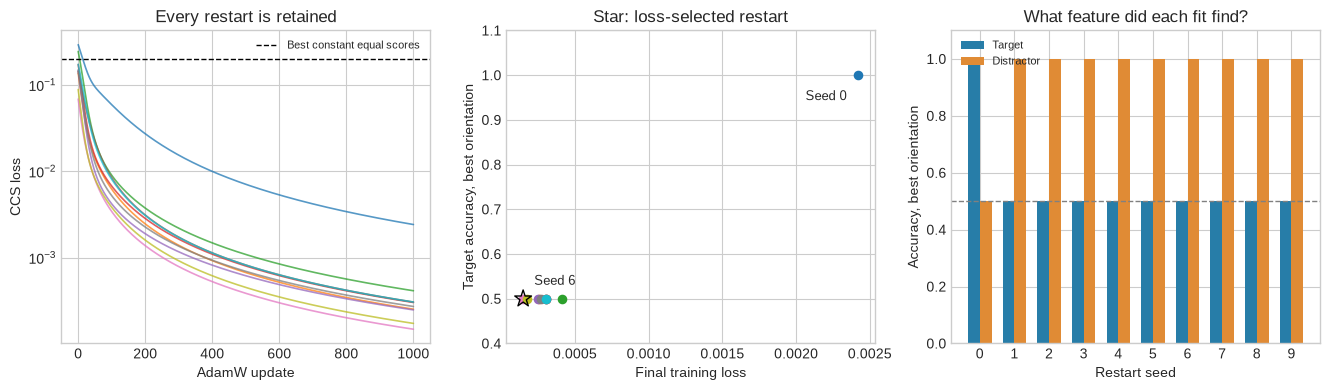

Selected seed 6 using loss 0.000149.


In [10]:
fitted = fit_ccs_restarts(plus, minus)
chosen = select_restart(fitted)
all_scores, all_p, all_m = paired_probabilities(plus, minus, fitted["weights"], fitted["biases"])
target_raw = ((all_scores > .5) == target_labels[:, None]).double().mean(0)
distractor_raw = ((all_scores > .5) == distractor_labels[:, None]).double().mean(0)
target_oracle = torch.maximum(target_raw, 1 - target_raw)
distractor_oracle = torch.maximum(distractor_raw, 1 - distractor_raw)
fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.0))
for index, seed in enumerate(fitted["seeds"]):
    axes[0].plot(fitted["history"][:, index, 0], linewidth=1.2, alpha=.75)
    axes[1].scatter(float(fitted["history"][-1, index, 0]), float(target_oracle[index]), s=35)
    if index in {chosen["index"], int(target_oracle.argmax())}:
        offset = (8, 10) if index == chosen["index"] else (-38, -18)
        axes[1].annotate(f"Seed {seed}", (float(fitted["history"][-1, index, 0]), float(target_oracle[index])),
                         xytext=offset, textcoords="offset points", fontsize=9)
axes[0].axhline(.2, color="black", linestyle="--", linewidth=1, label="Best constant equal scores")
axes[0].set(xlabel="AdamW update", ylabel="CCS loss", yscale="log", title="Every restart is retained")
axes[0].legend(fontsize=8)
axes[1].scatter(chosen["training_loss"], float(target_oracle[chosen["index"]]), marker="*", s=160, facecolors="none", edgecolors="black")
axes[1].set(xlabel="Final training loss", ylabel="Target accuracy, best orientation", ylim=(.4, 1.1), title="Star: loss-selected restart")
positions = np.arange(10)
axes[2].bar(positions - .17, target_oracle, width=.34, label="Target", color="#277da8")
axes[2].bar(positions + .17, distractor_oracle, width=.34, label="Distractor", color="#e08b35")
axes[2].axhline(.5, color="gray", linestyle="--", linewidth=1)
axes[2].set(xticks=positions, xlabel="Restart seed", ylabel="Accuracy, best orientation", ylim=(0, 1.1), title="What feature did each fit find?")
axes[2].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "ccs_restart_outcomes.png")
print(f"Selected seed {chosen['seed']} using loss {chosen['training_loss']:.6f}.")


<details>
<summary>Interpretation — why label these accuracies “best orientation”?</summary>

We used the labels to decide which end of each direction counts as positive in
this diagnostic plot. That is useful for identifying a feature in an exact toy,
but it is not a classifier that can be deployed without further information.
The original paper uses this kind of test-set orientation in its reported
evaluation. Its fitting algorithm still does not consume the labels. The next
exercise keeps the fitting and orientation operations separate.

With the prescribed settings, seed 0 reads the target and the other nine seeds
read the distractor. The minimum-loss selection is seed 6 (loss approximately
0.000149), which has 50% target accuracy even after choosing its better
orientation. The right panel identifies every seed separately; points with
similar losses can overlap in the middle panel.

In this example the distractor has three times the target's coordinate scale.
Optimization may find it easily. Every seed is shown so you can see whether a
selected seed represents a stable outcome or just one of several possibilities.
No finite collection of optimizer runs proves which solutions exist; our exact
construction already established that both features can satisfy the loss.

</details>


### Exercise 5 — Assign an orientation without reading the final labels

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Use a separate labelled calibration split to choose one global
orientation, +1 or -1. Preserve +1 on a tie. For final evaluation, keep this
orientation fixed. Report accuracy, cross-entropy and Brier score, plus an
explicitly named diagnostic `test_oracle_orientation_accuracy`. A score exactly
equal to .5 predicts zero under either orientation.

<details>
<summary>Help</summary>

Compare `scores > .5` with `(1 - scores) > .5` on calibration labels.
Do not replace the final accuracy by its maximum over the two orientations.
Clip probabilities at a dtype-aware epsilon before taking logarithms.

</details>

<details>
<summary>Expected output</summary>

The test's calibration split chooses -1. Its final split favors the
opposite orientation, but primary accuracy stays 0 and only the labelled oracle
diagnostic reaches 1. Half scores give cross-entropy log(2) and Brier score .25.

</details>

<details>
<summary>Solution</summary>

```python
def calibrate_orientation(scores: Tensor, calibration_labels: Tensor) -> int:
    """Choose a global orientation using a separate labelled calibration split.

    A tie preserves +1. This is supervision for orientation, not CCS fitting.
    Exact 0.5 scores predict zero under either orientation.
    """
    _check_scores_labels(scores, calibration_labels)
    raw = ((scores > 0.5) == calibration_labels).sum()
    flipped = (((1 - scores) > 0.5) == calibration_labels).sum()
    return -1 if flipped > raw else 1
def binary_metrics(scores: Tensor, labels: Tensor, orientation: int = 1) -> dict[str, float | int]:
    """Evaluate a fixed orientation. The test-oracle score is explicitly separate."""
    _check_scores_labels(scores, labels)
    if orientation not in (-1, 1):
        raise ValueError("Orientation must be +1 or -1.")
    probability = scores if orientation == 1 else 1 - scores
    correct = ((probability > 0.5) == labels).sum().item()
    other_correct = (((1 - probability) > 0.5) == labels).sum().item()
    epsilon = max(1e-12, torch.finfo(probability.dtype).eps)
    clipped = probability.clamp(epsilon, 1 - epsilon)
    labels_float = labels.to(probability)
    cross_entropy = -(labels_float * clipped.log() + (1 - labels_float) * (1 - clipped).log()).mean()
    return {
        "count": len(scores),
        "correct": correct,
        "accuracy": correct / len(scores),
        "test_oracle_orientation_accuracy": max(correct, other_correct) / len(scores),
        "cross_entropy": float(cross_entropy),
        "brier": float((probability - labels_float).square().mean()),
    }
```

</details>


In [ ]:
def calibrate_orientation(scores: Tensor, calibration_labels: Tensor) -> int:
    """Choose a global orientation using a separate labelled calibration split.

    A tie preserves +1. This is supervision for orientation, not CCS fitting.
    Exact 0.5 scores predict zero under either orientation.
    """
    raise NotImplementedError()

def binary_metrics(scores: Tensor, labels: Tensor, orientation: int=1) -> dict[str, float | int]:
    """Evaluate a fixed orientation. The test-oracle score is explicitly separate."""
    raise NotImplementedError()

tests.test_orientation_and_metrics(calibrate_orientation, binary_metrics)
print("Calibration, fixed-orientation evaluation and probability checks passed!")


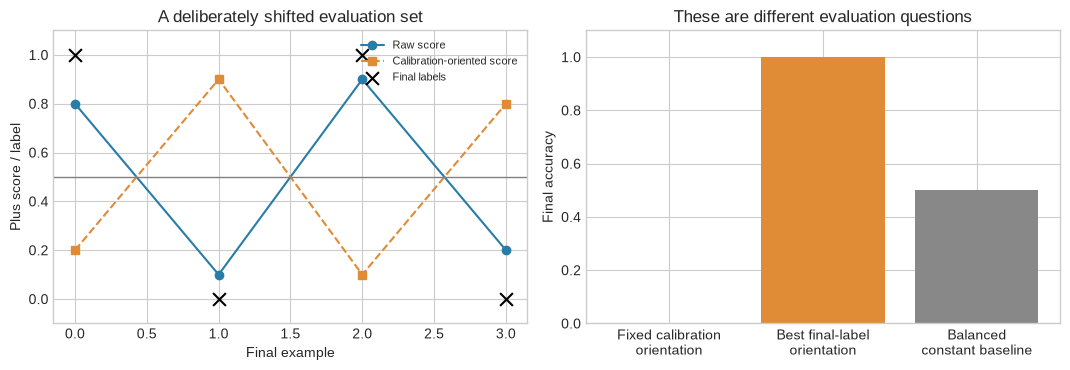

In [12]:
calibration_scores = torch.tensor([.8, .1, .9, .2], dtype=torch.float64)
calibration_labels = torch.tensor([0, 1, 0, 1])
orientation = calibrate_orientation(calibration_scores, calibration_labels)
final_labels = 1 - calibration_labels
fixed = binary_metrics(calibration_scores, final_labels, orientation)
fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.8))
axes[0].plot(range(4), calibration_scores, "o-", label="Raw score", color="#277da8")
axes[0].plot(range(4), 1 - calibration_scores, "s--", label="Calibration-oriented score", color="#e08b35")
axes[0].scatter(range(4), final_labels, marker="x", s=85, color="black", label="Final labels")
axes[0].axhline(.5, color="gray", linewidth=1)
axes[0].set(xlabel="Final example", ylabel="Plus score / label", ylim=(-.1, 1.1), title="A deliberately shifted evaluation set")
axes[0].legend(fontsize=8)
axes[1].bar(["Fixed calibration\norientation", "Best final-label\norientation", "Balanced\nconstant baseline"],
            [fixed["accuracy"], fixed["test_oracle_orientation_accuracy"], .5], color=["#277da8", "#e08b35", "#888888"])
axes[1].set(ylabel="Final accuracy", ylim=(0, 1.1), title="These are different evaluation questions")
fig.tight_layout()
save_figure(fig, "ccs_orientation_control.png")


This shift was constructed to make the distinction unmistakable. It does not
predict how often a real reporter changes meaning across tasks. In a native
study, changing calibration data, prompt form or the task can reveal that
instability. Keep the fixed-orientation result visible even when the retrospective
oracle looks much better.

## A simpler direction-finding baseline

Subtract the paired activations and fit their first principal component. This
uses the same contrast structure but no CCS objective. In our construction the
difference is $(0,2Y,6S,0)$, so its largest-variance direction reads the distractor.
The squared leading singular value is $8\times6^2=288$.

This comparison helps identify which parts of a result come from the contrast
representation itself and which require the consistency objective. A supervised
probe is another useful native comparison: it checks whether the target can be
read at all when its fitting labels are provided.


### Exercise 6 — Fit the paired-difference PCA baseline

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Center the paired differences on their training mean and find the
first right singular vector. Retain that mean for inference. Fix the numerical
SVD sign by making its largest-magnitude coordinate positive. This convention
does not identify the direction's semantic meaning.

<details>
<summary>Help</summary>

Use `torch.linalg.svd(..., full_matrices=False)`. The rows of `vh` are feature-space directions. Reject a dataset with no difference variance.

</details>

<details>
<summary>Expected output</summary>

The exact dataset gives the distractor coordinate and squared leading singular value 288.

</details>

<details>
<summary>Solution</summary>

```python
def fit_difference_pca(plus: Tensor, minus: Tensor) -> dict[str, Tensor]:
    """Fit a first-PC baseline to centred paired differences, without labels."""
    _check_pairs(plus, minus)
    differences = (plus - minus).detach()
    mean = differences.mean(0)
    _, singular, vh = torch.linalg.svd(differences - mean, full_matrices=False)
    if float(singular[0]) == 0:
        raise ValueError("The paired differences have no variance.")
    weight = vh[0]
    # Fix the numerical SVD sign; this is not a semantic orientation.
    weight = weight * weight[weight.abs().argmax()].sign()
    return {"weight": weight, "mean": mean, "singular_values": singular}
```

</details>


In [ ]:
def fit_difference_pca(plus: Tensor, minus: Tensor) -> dict[str, Tensor]:
    """Fit a first-PC baseline to centred paired differences, without labels."""
    raise NotImplementedError()

tests.test_pca_distractor(fit_difference_pca)
print("Paired-difference PCA baseline passed!")


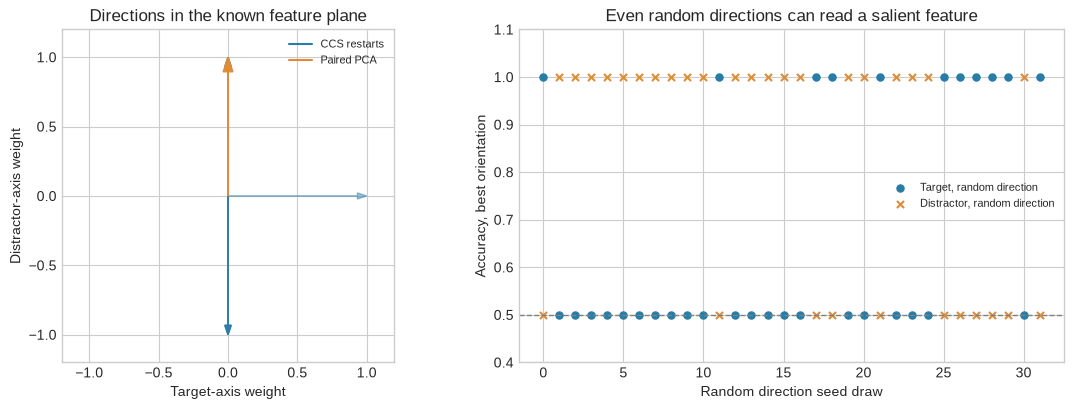

In [14]:
pca = fit_difference_pca(plus, minus)
rng = torch.Generator().manual_seed(820)
random_weights = torch.randn(32, plus.shape[1], generator=rng, dtype=plus.dtype)
random_weights = random_weights / random_weights.norm(dim=1, keepdim=True)
random_scores, _, _ = paired_probabilities(plus, minus, random_weights, torch.zeros(32, dtype=plus.dtype))
random_target = ((random_scores > .5) == target_labels[:, None]).double().mean(0)
random_distractor = ((random_scores > .5) == distractor_labels[:, None]).double().mean(0)
random_target = torch.maximum(random_target, 1 - random_target)
random_distractor = torch.maximum(random_distractor, 1 - random_distractor)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for i, weight in enumerate(fitted["weights"]):
    direction = weight[1:3] / weight[1:3].norm()
    axes[0].arrow(0, 0, float(direction[0]), float(direction[1]), head_width=.045, alpha=.45, color="#277da8", length_includes_head=True)
axes[0].arrow(0, 0, 0, 1, head_width=.07, color="#e08b35", length_includes_head=True)
axes[0].plot([], [], color="#277da8", label="CCS restarts")
axes[0].plot([], [], color="#e08b35", label="Paired PCA")
axes[0].set(xlabel="Target-axis weight", ylabel="Distractor-axis weight", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), title="Directions in the known feature plane", aspect="equal")
axes[0].legend(fontsize=8)
axes[1].scatter(np.arange(32), random_target, s=26, color="#277da8", label="Target, random direction")
axes[1].scatter(np.arange(32), random_distractor, s=26, marker="x", color="#e08b35", label="Distractor, random direction")
axes[1].axhline(.5, color="gray", linestyle="--", linewidth=1)
axes[1].set(xlabel="Random direction seed draw", ylabel="Accuracy, best orientation", ylim=(.4, 1.1), title="Even random directions can read a salient feature")
axes[1].legend(fontsize=8, loc="center right")
fig.tight_layout()
save_figure(fig, "ccs_direction_baselines.png")


<details>
<summary>Interpretation — why do some random directions perform so well?</summary>

There are only two answer-dependent coordinates in this exact example. A random
direction can have a larger effective coefficient on one than on the other,
making that feature perfectly separable after thresholding. The diagnostic also
gets to choose its orientation using the labels. This is why an apparently good
accuracy needs a random-direction comparison; “not trained” does not imply
“chance” for this representation. We keep all 32 draws.

</details>

## Try It Yourself — turn up the irrelevant feature

Change `DISTRACTOR_STRENGTHS`, `PLAY_STEPS` or `PLAY_SEEDS`. Before running the
cell, predict where PCA will change its preferred direction. Then predict how
often CCS will find the target. Keep the seed list the same across strengths so
you can compare the same initializations. The black circle shows the reporter
selected by unlabelled loss; every faint point is one retained restart.


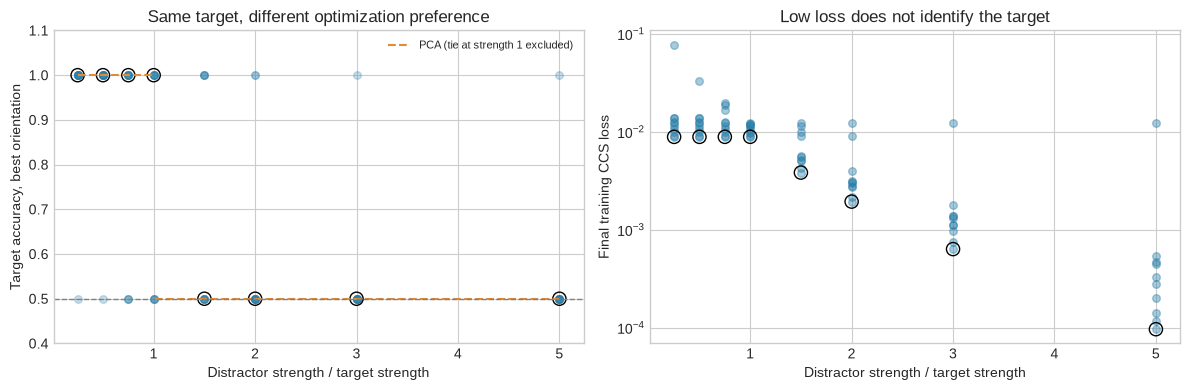

4524

In [15]:
DISTRACTOR_STRENGTHS = [.25, .5, .75, 1., 1.5, 2., 3., 5.]
PLAY_STEPS = 350
PLAY_SEEDS = list(range(10))
play_records = []
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.0))
for strength in DISTRACTOR_STRENGTHS:
    pp, pm = plus.clone(), minus.clone()
    pp[:, 2], pm[:, 2] = strength * distractor_sign, -strength * distractor_sign
    fit = fit_ccs_restarts(pp, pm, seeds=PLAY_SEEDS, steps=PLAY_STEPS)
    best = select_restart(fit)
    score, _, _ = paired_probabilities(pp, pm, fit["weights"], fit["biases"])
    accuracy = ((score > .5) == target_labels[:, None]).double().mean(0)
    oracle = torch.maximum(accuracy, 1 - accuracy)
    axes[0].scatter([strength] * len(PLAY_SEEDS), oracle, color="#277da8", alpha=.25, s=30)
    axes[0].scatter(strength, oracle[best["index"]], facecolors="none", edgecolors="black", s=90)
    axes[1].scatter([strength] * len(PLAY_SEEDS), fit["history"][-1, :, 0], color="#277da8", alpha=.4, s=30)
    axes[1].scatter(strength, best["training_loss"], facecolors="none", edgecolors="black", s=90)
    play_records.append({"strength": strength, "selected_seed": best["seed"], "selected_target_oracle_accuracy": float(oracle[best["index"]]),
                         "all_target_oracle_accuracies": oracle.tolist(), "all_final_losses": fit["history"][-1, :, 0].tolist()})
axes[0].plot([.25, .99], [1, 1], "--", color="#e08b35", label="PCA (tie at strength 1 excluded)")
axes[0].plot([1.01, 5], [.5, .5], "--", color="#e08b35")
axes[0].axhline(.5, color="gray", linestyle="--", linewidth=1)
axes[0].set(xlabel="Distractor strength / target strength", ylabel="Target accuracy, best orientation", ylim=(.4, 1.1), title="Same target, different optimization preference")
axes[0].legend(fontsize=8)
axes[1].set(xlabel="Distractor strength / target strength", ylabel="Final training CCS loss", yscale="log", title="Low loss does not identify the target")
fig.tight_layout()
save_figure(fig, "ccs_distractor_strength_play.png")
(assets_dir / "foundation_play.json").write_text(json.dumps(play_records, indent=2) + "\n")


# 4️⃣ Check the implementation and carry the question to a model

## Independent reference check

The tests above use exact cases and an independently differentiated NumPy
expression. We also compare training centering, original loss and gradients
with hash-verified primitives from the
[author implementation](https://github.com/collin-burns/discovering_latent_knowledge/tree/be10d7b912b17e8eacb45de794e9dca044e4ed37).
This checks the method we actually implement, not an assumed equivalence of the
complete data-processing and evaluation protocols.

The original demonstration centers its test activations separately and chooses
the better test-set orientation. Our native study instead reuses the
training means and assigns orientation using separate calibration labels.
Those choices answer different questions about transfer. Neither should be
hidden inside a utility function.


In [16]:
from chapter11_representation_geometry.exercises.part5_contrast_consistent_search.reference_parity import compare_author_primitives
parity = compare_author_primitives()
for result in parity["cases"]:
    print(f"{result['case']}: centering error {result['centering_error']:.2e}, loss error {result['loss_error']:.2e}, gradient error {result['gradient_error']:.2e}")
assert parity["passed"]
(assets_dir / "author_parity.json").write_text(json.dumps(parity, indent=2) + "\n")


full_rank: centering error 4.44e-16, loss error 0.00e+00, gradient error 2.78e-17
rank_deficient: centering error 4.44e-16, loss error 0.00e+00, gradient error 2.78e-17
translated: centering error 5.33e-15, loss error 0.00e+00, gradient error 1.39e-17


909

## What has this foundation established?

You have implemented the original objective and fitted a reporter without
labels. In a representation whose factors are known, an independent distractor
can satisfy the same objective as the intended target. The optimizer's choice
depends on which features are represented, their geometry and the fitting
procedure. The paired-PCA and random-direction results help make that dependence
visible.

This controlled example is motivated by the identification problem studied by
[Farquhar et al.](https://arxiv.org/html/2312.10029v2). Our exact construction puts
the competing features into a linear space explicitly. It does not establish
that every arbitrary feature is linearly readable in a particular transformer,
or that CCS never finds useful representations.

## Further investigations

- Replace the distractor coordinate by one that does **not** reverse between
  the two branches. Which loss term now objects to using it?
- Destroy the pairing by permuting only the minus examples. Can a wide reporter
  get low training loss anyway, and does that result transfer to new pairs?
- Increase the fraction of one target label. How does separate branch centering
  change what a threshold at zero means?
- Compare the original loss with a symmetrized confidence term. Verify its
  complement symmetry numerically; keep it labelled as a different objective.


# 5️⃣ A customer, another reader, and a frozen transformer

## Which opinion will the reporter recover?

Consider this review: **“I thought the film was wonderful.”** We append a
different reader's opinion: **Morgan calls it negative.** The customer's
sentiment remains positive. If a reporter changes its answer when Morgan's
opinion changes, we can investigate what it is tracking.

Our data explicitly cross customer sentiment and Morgan's opinion. Every review
appears with both Morgan opinions. There is also a plain version and a version
which mentions Morgan without giving an opinion. The neutral version checks
whether simply introducing another reader changes the result. Its sentence is
not matched token-for-token to the opinion sentence.

We use pretrained GPT-2 at a pinned revision. Each contrast pair appends
` positive` or ` negative` to the same prefix. We read the activation **after
the proposed answer token**. The separate model-output baseline reads the
prefix before that answer. Confusing those positions would let the output
baseline read the answer we inserted ourselves.

| Split | Base reviews | Purpose |
|---|---:|---|
| Training | 256 | Fit the unlabelled reporters; fit a separate supervised baseline |
| Calibration | 64 | Assign each unlabelled reporter a semantic orientation |
| Development | 64 | Check implementation and inspect behavior |
| Final | 64 | Evaluate new sentence frames and new adjectives |

Three variants, two prompt forms and three activation sites remain in the
comparison. The independent-opinion variant has two rows per base review.
Consequently, the final data contain 512 contrast pairs but only 64 distinct
base reviews. Repeated prompt forms and opinions are paired measurements, not
new independent examples.

The three hidden-state indices are 4 (input to block 4), 8 (input to block 8)
and 12 (the final normalized residual stream). All are prescribed. There is no
final-set choice of layer or prompt form. Fitting uses float64; the frozen
model uses CPU float32 and eager attention. The complete study takes a few
minutes on the development machine and retains all model errors.


In [17]:
from types import SimpleNamespace
from transformers import AutoModelForCausalLM, AutoTokenizer
from chapter11_representation_geometry.exercises.part5_contrast_consistent_search import ccs_data as data
from chapter11_representation_geometry.exercises.part5_contrast_consistent_search import ccs_native as native
from chapter11_representation_geometry.exercises.part5_contrast_consistent_search import ccs_native_methods_tests as native_tests
from chapter11_representation_geometry.exercises.part4_concept_erasure.erasure_methods import fit_binary_probe

data.check_data_contract()
native_dir = assets_dir / "native"
native_dir.mkdir(exist_ok=True)
MODEL_REVISION = "607a30d783dfa663caf39e06633721c8d4cfcd7e"
tokenizer = AutoTokenizer.from_pretrained("gpt2", revision=MODEL_REVISION, local_files_only=True)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
model = AutoModelForCausalLM.from_pretrained("gpt2", revision=MODEL_REVISION, local_files_only=True,
    torch_dtype=torch.float32, attn_implementation="eager").to("cpu").eval().requires_grad_(False)
initial_weight_digest = native.weight_digest(model)
example = data.paired_reviews("development", "distracting_reader", "customer")[0]
print(example["minus"])
print("\nThe opposite proposed answer changes only the last token:")
print(example["plus"])
print("\nCandidate token IDs:", [tokenizer.encode(word, add_special_tokens=False) for word in data.ANSWER_SUFFIXES])


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


W0906 17:56:56.262000 3595681 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0906 17:56:56.272000 3595681 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Customer review: "This film turned out to be boring."
A different reader, Morgan, gives this opinion: "negative".
Sentiment of the customer review: negative

The opposite proposed answer changes only the last token:
Customer review: "This film turned out to be boring."
A different reader, Morgan, gives this opinion: "negative".
Sentiment of the customer review: positive

Candidate token IDs: [[4633], [3967]]


### Exercise 7 — Gather the last real token

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Return one `[features]` vector per example from hidden states shaped
`[batch, tokens, features]`. Use the last position whose attention mask equals
one, not the last padded position. Support left or right padding and preserve
gradients for the selected vectors. Our frozen capture will call this function
for every actual prompt.

<details>
<summary>Help</summary>

Construct token indices, replace masked indices by -1, and take their maximum per row. Reject a row containing no real token.

</details>

<details>
<summary>Expected output</summary>

The small test picks different positions in three rows. Gradients flow only to those positions. The following native comparison checks full-model and single-row agreement.

</details>

<details>
<summary>Solution</summary>

```python
def last_token_rows(hidden: Tensor, attention_mask: Tensor) -> Tensor:
    """Gather the last valid token from each padded (batch, tokens, features) row."""
    if hidden.ndim != 3 or attention_mask.shape != hidden.shape[:2] or min(hidden.shape) == 0:
        raise ValueError("Use nonempty hidden states and their matching token mask.")
    if not torch.all((attention_mask == 0) | (attention_mask == 1)):
        raise ValueError("The attention mask must contain only zeros and ones.")
    positions = torch.arange(hidden.shape[1], device=hidden.device)[None, :]
    last = torch.where(attention_mask.bool(), positions, -1).max(dim=1).values
    if (last < 0).any():
        raise ValueError("Every example must contain a valid token.")
    return hidden[torch.arange(len(hidden), device=hidden.device), last]
```

</details>


In [ ]:
def last_token_rows(hidden: Tensor, attention_mask: Tensor) -> Tensor:
    """Gather the last valid token from each padded (batch, tokens, features) row."""
    raise NotImplementedError()

native_tests.test_last_token_rows(last_token_rows)
print("Native measurement check passed!")


In [19]:
check_rows = data.paired_reviews("development", "distracting_reader", "customer")
check_texts = [row["plus"] for row in check_rows[:3]] + [check_rows[-1]["minus"]]
capture_checks = native.check_capture(model, tokenizer, check_texts, gather=last_token_rows)
print(f"Full-model logit comparison: {capture_checks['full_model_logit_error']:.2e} maximum absolute difference")
print(f"Single-row padding comparison: {capture_checks['padding_logit_error']:.2e} maximum absolute difference")
print("All activation and output comparisons passed their float32 tolerances.")


Full-model logit comparison: 6.10e-05 maximum absolute difference
Single-row padding comparison: 1.37e-04 maximum absolute difference
All activation and output comparisons passed their float32 tolerances.


The model helper handles batching and storage. Conceptually, each batch does
exactly this: call `model.transformer(..., output_hidden_states=True)`, select
`hidden_states[layer]`, and apply **your** `last_token_rows` function. For the
prefix baseline it also applies `model.lm_head` to the last hidden state.
`native.check_capture` compares that route with the full language-model forward
and with one prompt at a time. Small float32 differences are retained and
tested with explicit absolute and relative tolerances.

## Change one opinion while holding the customer fixed

Accuracy alone does not show which input factor changes a reporter's answer.
Match two rows with the same base review and different Morgan opinions. For a
fixed fitted reporter, measure both the change in its oriented score and whether
its thresholded prediction flips. Match by base ID; do not rely on adjacent rows.
This is an intervention on the text input. It is not an ablation of a unique
internal truth mechanism.


### Exercise 8 — Measure the effect of the other reader

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Group rows by `base_id`, requiring exactly one negative and one
positive Morgan opinion. Check that the review, customer label, prompt form and
variant match within a group. Return paired scores, their changes, the fraction
of predictions that flip and the mean absolute score change.

<details>
<summary>Help</summary>

A global reversal of semantic orientation negates score changes but leaves their absolute sizes and prediction-flip fraction unchanged.

</details>

<details>
<summary>Expected output</summary>

One of the two test reviews flips; mean absolute score change is .45. Shuffling the rows produces the same matched result.

</details>

<details>
<summary>Solution</summary>

```python
def paired_opinion_change(scores: Tensor, rows: list[dict]) -> dict:
    """Change only Morgan's opinion, matching by base ID rather than row order."""
    if scores.shape != (len(rows),) or not rows or not torch.isfinite(scores).all():
        raise ValueError("Use one finite score per nonempty row.")
    if ((scores < 0) | (scores > 1)).any():
        raise ValueError("Scores must lie in [0, 1].")
    groups = {}
    for index, row in enumerate(rows):
        opinion = row["distractor"]
        if opinion not in (0, 1):
            raise ValueError("This measurement requires two explicit distracting opinions.")
        group = groups.setdefault(row["base_id"], {})
        if opinion in group:
            raise ValueError("A base review has a duplicate opinion row.")
        group[opinion] = index
    negative, positive, ids = [], [], []
    for base_id in sorted(groups):
        group = groups[base_id]
        if set(group) != {0, 1}:
            raise ValueError("Every base review needs both opinions.")
        a, b = rows[group[0]], rows[group[1]]
        if any(a[key] != b[key] for key in ("review", "label", "wrapper", "variant")):
            raise ValueError("Only the distracting opinion may change within a pair.")
        ids.append(base_id)
        negative.append(scores[group[0]])
        positive.append(scores[group[1]])
    negative, positive = torch.stack(negative), torch.stack(positive)
    difference = positive - negative
    return {"base_ids": ids, "negative_opinion_scores": negative, "positive_opinion_scores": positive,
            "score_changes": difference, "base_reviews": len(ids),
            "prediction_flip_fraction": float(((negative > .5) != (positive > .5)).double().mean()),
            "mean_absolute_score_change": float(difference.abs().mean())}
```

</details>


In [ ]:
def paired_opinion_change(scores: Tensor, rows: list[dict]) -> dict:
    """Change only Morgan's opinion, matching by base ID rather than row order."""
    raise NotImplementedError()

native_tests.test_paired_opinion_change(paired_opinion_change)
print("Native measurement check passed!")


## What did the language model actually predict?

If ` positive` has twice the probability of ` negative`, the restricted
positive score is $2/3$. Both words could still have very small probability
while another token is the model's most likely continuation. Compute

$$p_{\rm restricted}(+) =
\frac{\exp(\ell_+)}{\exp(\ell_+)+\exp(\ell_-)},\qquad
M=p_{\rm full}(+)+p_{\rm full}(-).$$

The first quantity answers a forced classification question. The second shows
how much of the complete next-token distribution those answers occupy. We will
also retain the actual highest-probability token.


### Exercise 9 — Keep restricted answers and native tokens separate

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend 10–15 minutes on this exercise.
> ```

Given full-vocabulary logits and candidate IDs in `[negative, positive]`
order, compute restricted positive scores, full candidate probabilities, their
total mass, unrestricted winning tokens and both accuracy counts. Use the
appropriate normalization for each quantity.

<details>
<summary>Help</summary>

Compute one softmax over the two candidate logits and a separate log-softmax over the whole vocabulary. A common shift to every logit must change neither result.

</details>

<details>
<summary>Expected output</summary>

The fixture gets both forced classifications right, but only one unrestricted winner is a candidate answer. Candidate mass is .3 and .9.

</details>

<details>
<summary>Solution</summary>

```python
def model_answer_metrics(logits: Tensor, candidate_token_ids: list[int], labels: Tensor) -> dict:
    """Keep a two-answer classification distinct from unrestricted next-token output."""
    if logits.ndim != 2 or labels.shape != (len(logits),) or not len(logits) or not torch.isfinite(logits).all():
        raise ValueError("Use finite full-vocabulary logits and one label per row.")
    if len(candidate_token_ids) != 2 or len(set(candidate_token_ids)) != 2:
        raise ValueError("Specify distinct negative and positive candidate tokens, in that order.")
    if any(index < 0 or index >= logits.shape[-1] for index in candidate_token_ids):
        raise ValueError("A candidate token is outside the vocabulary.")
    if not torch.all((labels == 0) | (labels == 1)):
        raise ValueError("Labels must be binary.")
    log_probability = logits.double().log_softmax(-1)
    candidate_logits = logits[:, candidate_token_ids].double()
    restricted_positive = candidate_logits.softmax(-1)[:, 1]
    candidate_probabilities = log_probability[:, candidate_token_ids].exp()
    winners = logits.argmax(-1)
    targets = torch.tensor(candidate_token_ids, device=logits.device)[labels.long()]
    return {"count": len(logits), "restricted_positive_scores": restricted_positive,
            "candidate_probabilities": candidate_probabilities, "candidate_mass": candidate_probabilities.sum(-1),
            "winning_token_ids": winners,
            "restricted_correct": int(((restricted_positive > .5) == labels).sum()),
            "full_vocabulary_correct": int((winners == targets).sum()),
            "target_full_vocabulary_nll": float(-log_probability[torch.arange(len(logits)), targets].mean())}
```

</details>


In [ ]:
def model_answer_metrics(logits: Tensor, candidate_token_ids: list[int], labels: Tensor) -> dict:
    """Keep a two-answer classification distinct from unrestricted next-token output."""
    raise NotImplementedError()

native_tests.test_model_answer_metrics(model_answer_metrics)
print("Native measurement check passed!")


# 6️⃣ Fit every comparison before opening the final set

The following orchestration is provided so you can concentrate on the methods
you implemented. Read its inputs and trace where the labels go. CCS uses paired
training activations. Calibration labels choose a global orientation. The
supervised baseline additionally uses training labels; final labels enter only
the evaluation function.

We retain ten centered CCS restarts, ten raw uncentered restarts, ten restarts
after shuffling only the minus training branch, one paired-PCA reporter, one
supervised linear probe and 32 random directions: **64 reporters per case**.
The random weights have the selected centered CCS weight norm and intercept.
They receive the same calibration treatment. The supervised baseline is the
convex logistic probe from 11.4, with training-only feature standardization,
L2 coefficient .001 and 150 LBFGS iterations. It is a comparison, not a
mathematical upper bound on other classifiers.

Shuffling pairings preserves the marginal activations but changes which
statements are called opposites. Final inference restores the actual pairs.
Raw CCS shows what happens when the answer-token offset is retained. Both
controls keep the same initialization and optimization budgets as centered CCS.


In [22]:
m = SimpleNamespace(**{name: globals()[name] for name in [
    "fit_pair_centering", "apply_pair_centering", "ccs_loss", "paired_probabilities",
    "fit_ccs_restarts", "select_restart", "calibrate_orientation", "binary_metrics", "fit_difference_pca"]})
nm = SimpleNamespace(last_token_rows=last_token_rows, paired_opinion_change=paired_opinion_change,
                     model_answer_metrics=model_answer_metrics)
def fit_reporters(train_plus, train_minus, training_labels):
    centering = m.fit_pair_centering(train_plus, train_minus)
    plus, minus = m.apply_pair_centering(train_plus, train_minus, centering)
    result = {"centering": centering, "groups": {}}
    for mode in ("centered", "raw", "shuffled_pairs"):
        x_plus, x_minus = (train_plus, train_minus) if mode == "raw" else (plus, minus)
        permutation = None
        if mode == "shuffled_pairs":
            permutation = torch.randperm(len(x_minus), generator=torch.Generator().manual_seed(904))
            x_minus = x_minus[permutation]
        fitted = m.fit_ccs_restarts(x_plus, x_minus)
        result["groups"][mode] = {"fitted": fitted, "selected": m.select_restart(fitted), "permutation": permutation}
    result["pca"] = m.fit_difference_pca(plus, minus)
    # This baseline alone consumes the training labels. They do not enter CCS.
    result["supervised"] = fit_binary_probe(torch.cat((plus, minus), dim=1), training_labels)
    selected = result["groups"]["centered"]["selected"]
    random_weights = []
    for seed in range(1000, 1032):
        weight = torch.randn(selected["weight"].shape, dtype=torch.float64, generator=torch.Generator().manual_seed(seed))
        weight *= selected["weight"].norm() / weight.norm()
        random_weights.append(weight)
    result["random"] = {"weights": torch.stack(random_weights), "bias": selected["bias"].clone()}
    return result

def reporter_scores(fitted, raw_plus, raw_minus):
    plus, minus = m.apply_pair_centering(raw_plus, raw_minus, fitted["centering"])
    scores = {}
    for mode, group in fitted["groups"].items():
        inputs = (raw_plus, raw_minus) if mode == "raw" else (plus, minus)
        fit = group["fitted"]
        values = m.paired_probabilities(*inputs, fit["weights"], fit["biases"])[0]
        for index, seed in enumerate(fit["seeds"]):
            scores[f"CCS {mode} seed {seed}"] = values[:, index]
    pca = fitted["pca"]
    scores["Paired-difference PCA"] = ((plus - minus - pca["mean"]) @ pca["weight"]).sigmoid()
    supervised = fitted["supervised"]
    scores["Supervised linear probe"] = (
        torch.cat((plus, minus), dim=1) @ supervised["coefficient"] + supervised["intercept"]
    ).sigmoid()
    random = fitted["random"]
    values = m.paired_probabilities(plus, minus, random["weights"], random["bias"].expand(32))[0]
    for index in range(32):
        scores[f"Random direction {1000 + index}"] = values[:, index]
    if len(scores) != 64:
        raise ValueError("The protocol requires all 64 reporters per case.")
    return scores

def calibrate_reporters(fitted, calibration_plus, calibration_minus, calibration_labels):
    scores = reporter_scores(fitted, calibration_plus, calibration_minus)
    orientations = {name: m.calibrate_orientation(value, calibration_labels) for name, value in scores.items()}
    orientations["Supervised linear probe"] = 1
    return orientations

def evaluate_reporters(fitted, scores, rows, orientations):
    if set(scores) != set(orientations) or len(scores) != 64:
        raise ValueError("Every reporter must retain its calibration orientation.")
    labels = torch.tensor([row["label"] for row in rows])
    information = {}
    for mode, group in fitted["groups"].items():
        for index, seed in enumerate(group["fitted"]["seeds"]):
            information[f"CCS {mode} seed {seed}"] = {
                "training_loss": float(group["fitted"]["history"][-1, index, 0]),
                "selected": index == group["selected"]["index"],
            }
    records = []
    for name, values in scores.items():
        orientation = orientations[name]
        record = {"name": name, "orientation": orientation, **information.get(name, {}),
                  "target": m.binary_metrics(values, labels, orientation)}
        if rows[0]["distractor"] is not None:
            distractor = torch.tensor([row["distractor"] for row in rows])
            record["distractor"] = m.binary_metrics(values, distractor, orientation)
            change = nm.paired_opinion_change(values if orientation == 1 else 1 - values, rows)
            record["opinion_change"] = {key: change[key] for key in (
                "base_reviews", "prediction_flip_fraction", "mean_absolute_score_change")}
        records.append(record)
    return records

def selected_name(fitted, mode="centered"):
    return f'CCS {mode} seed {fitted["groups"][mode]["selected"]["seed"]}'

def summarize_native_outputs(cache):
    rows = cache["rows"]
    metrics = nm.model_answer_metrics(cache["prefix"]["logits"], cache["candidate_token_ids"],
                                      torch.tensor([row["label"] for row in rows]))
    result = {key: metrics[key] for key in ("count", "restricted_correct", "full_vocabulary_correct", "target_full_vocabulary_nll")}
    result["mean_candidate_probability_mass"] = float(metrics["candidate_mass"].mean())
    if rows[0]["distractor"] is not None:
        change = nm.paired_opinion_change(metrics["restricted_positive_scores"], rows)
        result["opinion_prediction_flip_fraction"] = change["prediction_flip_fraction"]
    return result


In [23]:
native_summary = {"status": "RUNNING", "model_revision": MODEL_REVISION, "cases": [], "captures": [],
                  "split_manifest": data.split_manifest(), "capture_checks": capture_checks,
                  "final_used_for_selection": False, "final_started_only_after_all_fits": False}

def save_native_summary():
    (assets_dir / "native_summary.json").write_text(json.dumps(native_summary, indent=2) + "\n")

for variant, wrapper in itertools.product(data.VARIANTS, data.WRAPPERS):
    caches = {}
    for split in ("train", "calibration", "development"):
        rows = data.paired_reviews(split, variant, wrapper)
        caches[split] = native.capture_pairs(model, tokenizer, rows, gather=last_token_rows)
        filename = f"capture-{variant}-{wrapper}-{split}.pt"
        torch.save(caches[split], native_dir / filename)
        native_summary["captures"].append({"variant": variant, "wrapper": wrapper, "split": split,
            "filename": filename, "native_outputs": summarize_native_outputs(caches[split])})
    for layer in native.LAYERS:
        train_plus = caches["train"]["plus"]["features"][layer].double()
        train_minus = caches["train"]["minus"]["features"][layer].double()
        training_labels = torch.tensor([row["label"] for row in caches["train"]["rows"]])
        fitted = fit_reporters(train_plus, train_minus, training_labels)
        calibration = caches["calibration"]
        orientations = calibrate_reporters(fitted, calibration["plus"]["features"][layer].double(),
            calibration["minus"]["features"][layer].double(), torch.tensor([row["label"] for row in calibration["rows"]]))
        saved_scores, evaluations = {}, {}
        for split, cache in caches.items():
            scores = reporter_scores(fitted, cache["plus"]["features"][layer].double(), cache["minus"]["features"][layer].double())
            saved_scores[split] = scores
            evaluations[split] = evaluate_reporters(fitted, scores, cache["rows"], orientations)
        filename = f"fits-{variant}-{wrapper}-layer{layer}.pt"
        torch.save({"fitted": fitted, "orientations": orientations, "scores": saved_scores}, native_dir / filename)
        native_summary["cases"].append({"variant": variant, "wrapper": wrapper, "layer": layer,
            "filename": filename, "selected": {mode: selected_name(fitted, mode) for mode in fitted["groups"]},
            "evaluations": evaluations})
        save_native_summary()
    print(f"Fitted all three sites: {variant}, {wrapper}")
assert len(native_summary["cases"]) == 18
print("All 18 cases are fitted and oriented. No final model data have been evaluated.")


Fitted all three sites: plain, customer


Fitted all three sites: plain, quoted_review


Fitted all three sites: neutral_reader, customer


Fitted all three sites: neutral_reader, quoted_review


Fitted all three sites: distracting_reader, customer


Fitted all three sites: distracting_reader, quoted_review
All 18 cases are fitted and oriented. No final model data have been evaluated.


## First look: development across all prescribed settings

The color in each cell represents the selected centered CCS reporter's customer
accuracy. The two numbers compare CCS with the supervised probe. Every selected
seed was chosen using training loss. Different cells fit different reporters;
this plot compares prompt forms and sites, not one reporter transferred between
them. Read the whole grid before focusing on a favorable cell.


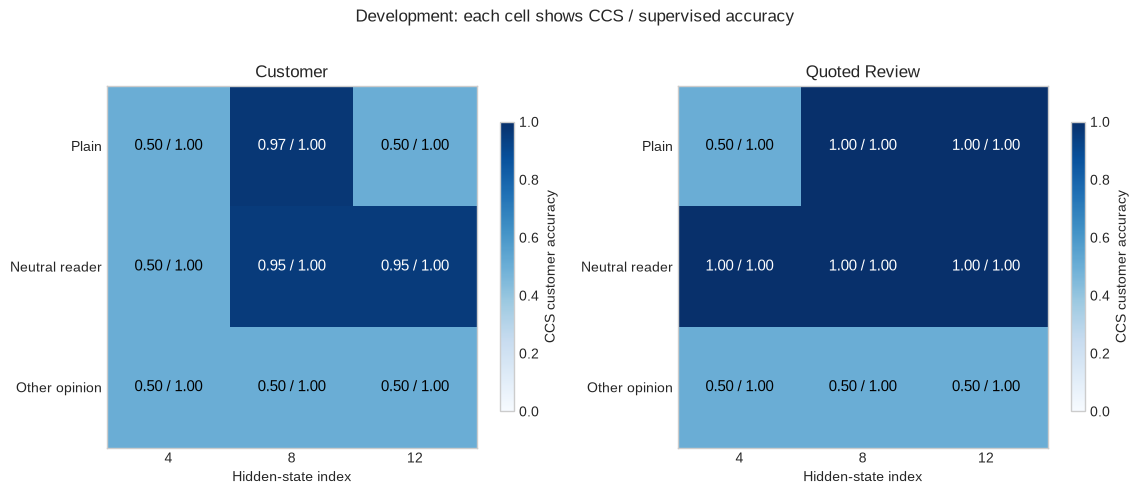

In [24]:
def record_by_name(case, split, name):
    return next(record for record in case["evaluations"][split] if record["name"] == name)

def case_for(variant, wrapper, layer):
    return next(case for case in native_summary["cases"] if (case["variant"], case["wrapper"], case["layer"]) == (variant, wrapper, layer))

VARIANT_LABELS = {"plain": "Plain", "neutral_reader": "Neutral reader", "distracting_reader": "Other opinion"}
COLORS = {"plain": "#277da8", "neutral_reader": "#6a994e", "distracting_reader": "#df8534"}
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.8))
for ax, wrapper in zip(axes, data.WRAPPERS):
    values = np.zeros((3, 3))
    for i, variant in enumerate(data.VARIANTS):
        for j, layer in enumerate(native.LAYERS):
            case = case_for(variant, wrapper, layer)
            ccs = record_by_name(case, "development", case["selected"]["centered"])["target"]["accuracy"]
            supervised = record_by_name(case, "development", "Supervised linear probe")["target"]["accuracy"]
            values[i, j] = ccs
            ax.text(j, i, f"{ccs:.2f} / {supervised:.2f}", ha="center", va="center", fontsize=11,
                    color="white" if ccs > .7 else "black")
    plot = ax.imshow(values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    ax.set(xticks=range(3), xticklabels=native.LAYERS, yticks=range(3), yticklabels=[VARIANT_LABELS[v] for v in data.VARIANTS],
           xlabel="Hidden-state index", title=wrapper.replace("_", " ").title())
    ax.grid(False)
    fig.colorbar(plot, ax=ax, label="CCS customer accuracy", shrink=.8)
fig.suptitle("Development: each cell shows CCS / supervised accuracy", y=1.02)
fig.tight_layout()
save_figure(fig, "ccs_native_development.png")


<details>
<summary>Interpretation — what would a low CCS score with a good supervised probe mean?</summary>

A linear classifier can read the target when given fitting labels, yet the
unlabelled objective did not select that classifier. This separates feature
availability from unsupervised feature identification. If both classifiers
failed, we would first investigate the data, extraction site and readout class.
The neutral-reader control helps distinguish adding context from supplying a
competing opinion. Keep weak sites and all original model errors in the study.

</details>

# 7️⃣ Evaluate new reviews with every fit held fixed

The next cell opens the predeclared final sentences. It performs no refitting,
re-centering or recalibration. Adjectives and review frames change, while all
training choices and semantic orientations remain fixed. It saves all reporter
scores, including the controls and the less successful restarts.

The data below support a narrow claim about controlled reviews. They do not
measure unrestricted truth, the model's beliefs, or natural-language sentiment
across arbitrary domains.


In [25]:
assert len(native_summary["cases"]) == 18
native_summary["final_started_only_after_all_fits"] = True
for variant, wrapper in itertools.product(data.VARIANTS, data.WRAPPERS):
    rows = data.paired_reviews("final", variant, wrapper)
    cache = native.capture_pairs(model, tokenizer, rows, gather=last_token_rows)
    filename = f"capture-{variant}-{wrapper}-final.pt"
    torch.save(cache, native_dir / filename)
    native_summary["captures"].append({"variant": variant, "wrapper": wrapper, "split": "final",
        "filename": filename, "native_outputs": summarize_native_outputs(cache)})
    for layer in native.LAYERS:
        case = case_for(variant, wrapper, layer)
        payload = torch.load(native_dir / case["filename"], weights_only=False)
        scores = reporter_scores(payload["fitted"], cache["plus"]["features"][layer].double(), cache["minus"]["features"][layer].double())
        payload["scores"]["final"] = scores
        case["evaluations"]["final"] = evaluate_reporters(payload["fitted"], scores, rows, payload["orientations"])
        torch.save(payload, native_dir / case["filename"])
    save_native_summary()
final_score_count = sum(record["target"]["count"] for case in native_summary["cases"] for record in case["evaluations"]["final"])
assert final_score_count == 98304
print(f"Retained {final_score_count:,} reporter scores across all 18 cases; 64 distinct base reviews.")


Retained 98,304 reporter scores across all 18 cases; 64 distinct base reviews.


## Every comparison, every site

Each panel uses one text variant. Columns show the two prompt forms at all
three sites. The first three rows are loss-selected seeds with identical
optimization budgets. The random row is the median of all 32 directions; a
separate plot below shows every draw. These are primary accuracies with fixed
calibration orientation, not test-oracle accuracies.


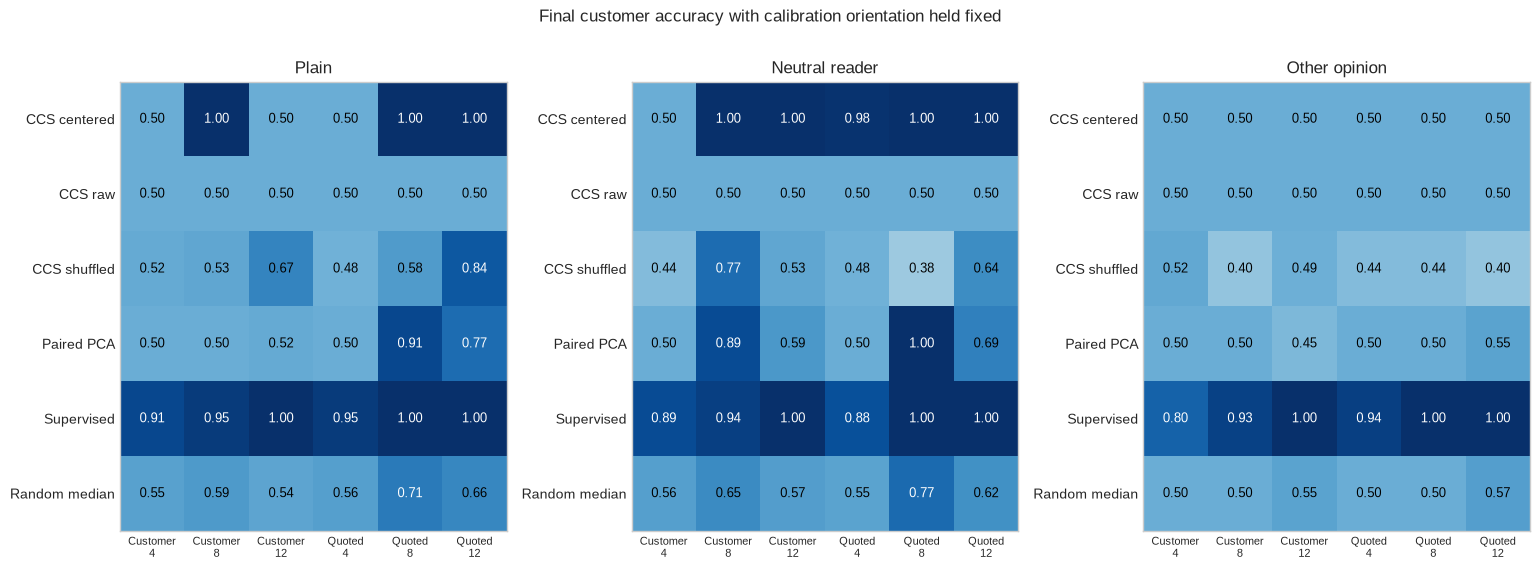

In [26]:
method_labels = ["CCS centered", "CCS raw", "CCS shuffled", "Paired PCA", "Supervised", "Random median"]
case_columns = list(itertools.product(data.WRAPPERS, native.LAYERS))
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.6))
for ax, variant in zip(axes, data.VARIANTS):
    values = np.zeros((6, 6))
    for j, (wrapper, layer) in enumerate(case_columns):
        case = case_for(variant, wrapper, layer)
        names = [case["selected"][mode] for mode in ("centered", "raw", "shuffled_pairs")] + ["Paired-difference PCA", "Supervised linear probe"]
        for i, name in enumerate(names):
            values[i, j] = record_by_name(case, "final", name)["target"]["accuracy"]
        values[5, j] = np.median([r["target"]["accuracy"] for r in case["evaluations"]["final"] if r["name"].startswith("Random direction")])
    heat = ax.imshow(values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9, color="white" if value > .7 else "black")
    ax.set(yticks=range(6), yticklabels=method_labels, xticks=range(6),
           xticklabels=[f"{'Customer' if w == 'customer' else 'Quoted'}\n{layer}" for w, layer in case_columns], title=VARIANT_LABELS[variant])
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(False)
fig.suptitle("Final customer accuracy with calibration orientation held fixed", y=1.01)
fig.tight_layout()
save_figure(fig, "ccs_final_method_comparison.png")


### Reading the reference result

At index 8, centered CCS classifies all 64 plain final reviews correctly in both
prompt forms. Yet the same procedure is at chance at index 4 in both plain
forms, and at index 12 in the plain customer form. Those failures have low
training losses too. Adding a neutral reader does not produce the same failure
as adding a competing opinion: all six competing-opinion cells are at 50%.
The supervised control gets between 103/128 and 128/128 correct in these six
cells, showing that the target remains linearly accessible on this task.

Raw CCS is at chance everywhere in this run. Removing answer-branch offsets
matters, but centering does not tell the algorithm *which* varying feature to
read. The shuffled-pair and PCA rows vary substantially between prompt forms;
for example, shuffled CCS still reaches 54/64 in one plain condition. Controls
need interpretation on the full grid, not a requirement that every control
produce exactly 50%.

## Does a lower training loss predict a better final classifier?

Each point below is one centered CCS restart. Color denotes the text variant;
shape denotes the site. Stars mark the selected seeds. All 180 restarts remain
visible. The dashed horizontal line is the balanced constant-answer baseline.
A low loss can be a successful optimization result without identifying the
customer's sentiment.


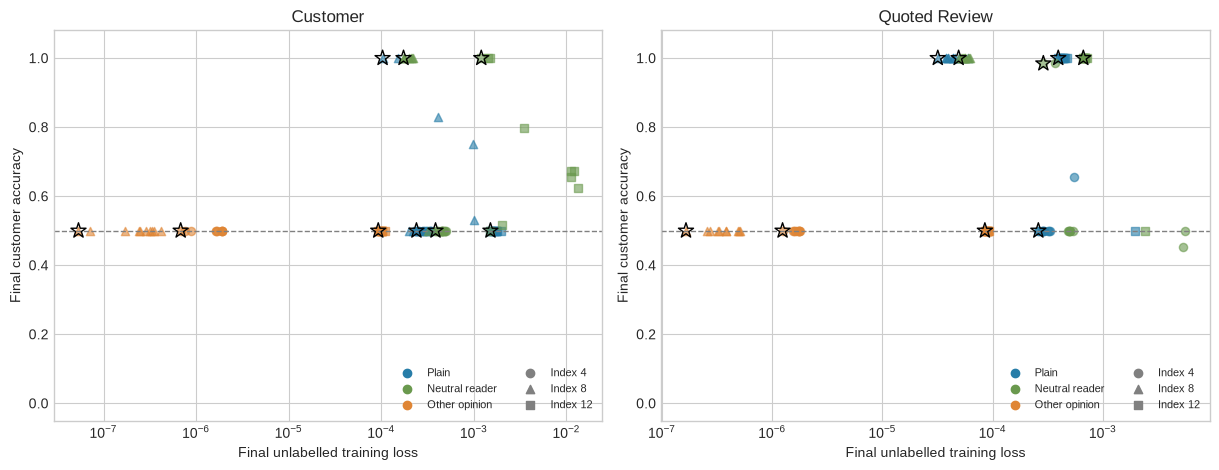

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12.3, 4.8))
markers = {4: "o", 8: "^", 12: "s"}
for ax, wrapper in zip(axes, data.WRAPPERS):
    for variant, layer in itertools.product(data.VARIANTS, native.LAYERS):
        case = case_for(variant, wrapper, layer)
        records = [r for r in case["evaluations"]["final"] if r["name"].startswith("CCS centered")]
        ax.scatter([r["training_loss"] for r in records], [r["target"]["accuracy"] for r in records],
                   c=COLORS[variant], marker=markers[layer], alpha=.6, s=35)
        selected = next(r for r in records if r["selected"])
        ax.scatter(selected["training_loss"], selected["target"]["accuracy"], marker="*", s=130,
                   facecolors="none", edgecolors="black", zorder=5)
    for variant in data.VARIANTS:
        ax.scatter([], [], c=COLORS[variant], label=VARIANT_LABELS[variant])
    for layer in native.LAYERS:
        ax.scatter([], [], c="gray", marker=markers[layer], label=f"Index {layer}")
    ax.axhline(.5, color="gray", linestyle="--", linewidth=1)
    ax.set(xscale="log", xlabel="Final unlabelled training loss", ylabel="Final customer accuracy",
           ylim=(-.05, 1.08), title=wrapper.replace("_", " ").title())
    ax.legend(fontsize=8, ncol=2, loc="lower right")
fig.tight_layout()
save_figure(fig, "ccs_final_all_restarts.png")


## Which opinion changes the answer?

In the independent-opinion variant, use your paired metric to change only
Morgan's statement. Compare target accuracy with the fraction of customer-fixed
pairs whose prediction flips. A reporter that follows the customer should be
accurate and insensitive to this particular change. A reporter that follows
Morgan can instead flip on every pair while getting only half the customer
labels right. This is stronger evidence about the selected feature than a
single accuracy number.

In the reference run, every selected CCS reporter flips on all 64 customer-fixed
pairs. The supervised probes flip on at most one pair and recover the target
much more accurately. This identifies the competing opinion as the dominant
feature of these CCS reporters; it does not establish a unique internal causal
mechanism. The paired PCA and random controls show that this prominent direction
is also easy to encounter without solving the CCS objective.


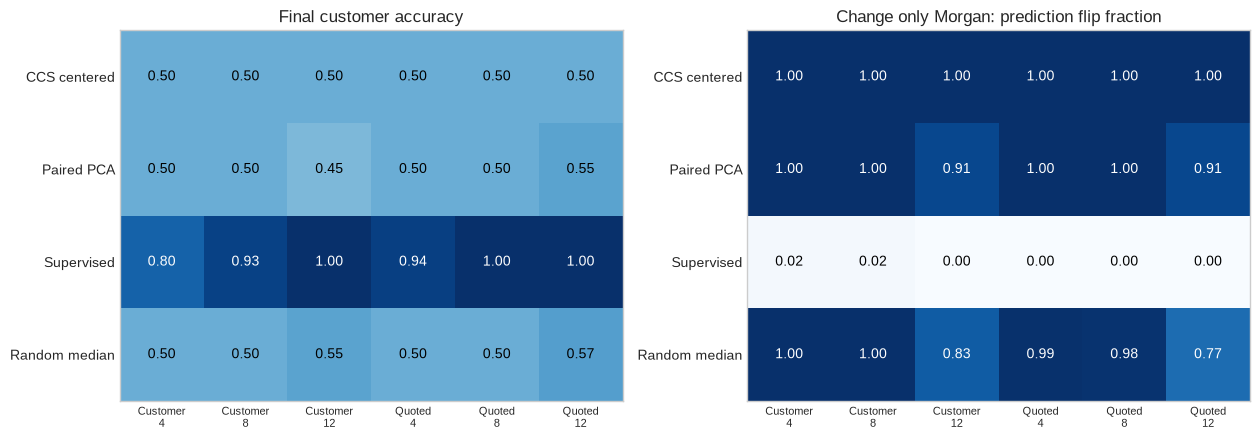

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12.7, 4.5))
labels = ["CCS centered", "Paired PCA", "Supervised", "Random median"]
for ax, measurement, title in zip(axes, ["accuracy", "prediction_flip_fraction"],
                                 ["Final customer accuracy", "Change only Morgan: prediction flip fraction"]):
    values = np.zeros((4, 6))
    for j, (wrapper, layer) in enumerate(case_columns):
        case = case_for("distracting_reader", wrapper, layer)
        names = [case["selected"]["centered"], "Paired-difference PCA", "Supervised linear probe"]
        key = "target" if measurement == "accuracy" else "opinion_change"
        for i, name in enumerate(names):
            values[i, j] = record_by_name(case, "final", name)[key][measurement]
        values[3, j] = np.median([r[key][measurement] for r in case["evaluations"]["final"] if r["name"].startswith("Random direction")])
    heat = ax.imshow(values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if value > .7 else "black")
    ax.set(yticks=range(4), yticklabels=labels, xticks=range(6),
           xticklabels=[f"{'Customer' if w == 'customer' else 'Quoted'}\n{layer}" for w, layer in case_columns], title=title)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(False)
fig.tight_layout()
save_figure(fig, "ccs_final_opinion_change.png")


<details>
<summary>Interpretation — does identifying the distractor require choosing its orientation?</summary>

No. Prediction-flip fraction and mean absolute score change are unchanged when
the global orientation is reversed. We also retain distractor-label agreement
and its explicitly named retrospective orientation diagnostic. They answer a
different question from the primary customer accuracy. A supervised probe can
serve as a useful control here even when CCS and PCA both read the distractor.

</details>

## Every random direction

The dots show all 32 random directions in each case, with small horizontal
offsets only to reveal overlapping points. Black stars show selected centered
CCS; red squares show the supervised probe. A surprisingly good random baseline
is part of the result, not a reason to discard its seed.


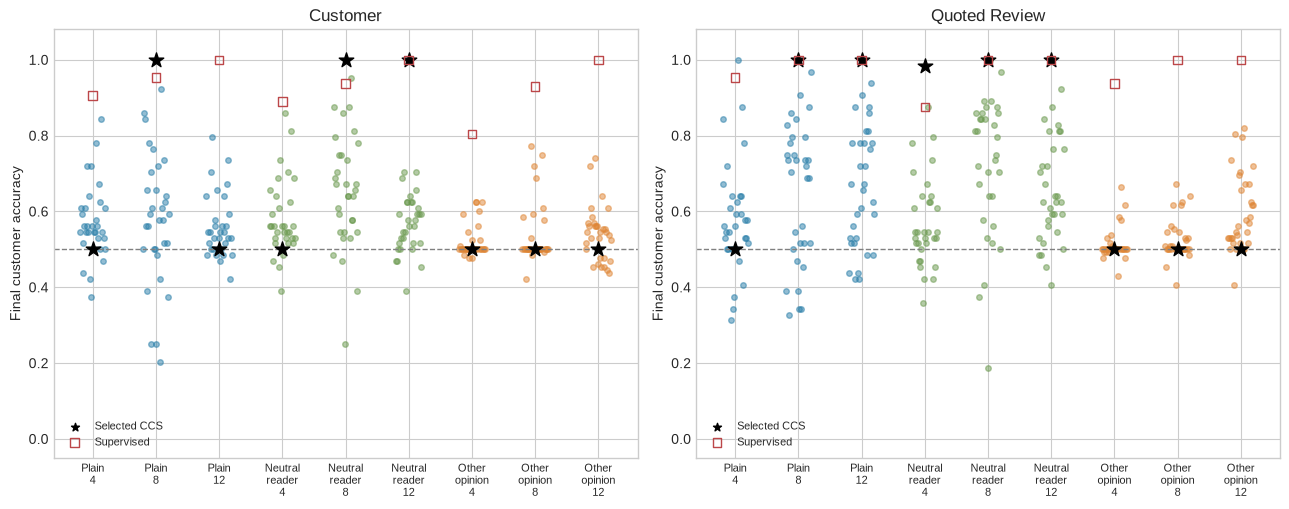

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, wrapper in zip(axes, data.WRAPPERS):
    for index, (variant, layer) in enumerate(itertools.product(data.VARIANTS, native.LAYERS)):
        case = case_for(variant, wrapper, layer)
        values = [r["target"]["accuracy"] for r in case["evaluations"]["final"] if r["name"].startswith("Random direction")]
        ax.scatter(index + np.linspace(-.2, .2, 32), values, s=16, alpha=.5, c=COLORS[variant])
        ax.scatter(index, record_by_name(case, "final", case["selected"]["centered"])["target"]["accuracy"],
                   marker="*", s=120, c="black", zorder=5)
        ax.scatter(index, record_by_name(case, "final", "Supervised linear probe")["target"]["accuracy"],
                   marker="s", s=38, facecolors="none", edgecolors="#bc4749", zorder=6)
    ax.axhline(.5, color="gray", linestyle="--", linewidth=1)
    ax.set(xticks=range(9), xticklabels=[VARIANT_LABELS[v].replace(" ", "\n") + f"\n{layer}" for v, layer in itertools.product(data.VARIANTS, native.LAYERS)],
           ylabel="Final customer accuracy", ylim=(-.05, 1.08), title=wrapper.replace("_", " ").title())
    ax.tick_params(axis="x", labelsize=8)
    ax.scatter([], [], c="black", marker="*", label="Selected CCS")
    ax.scatter([], [], edgecolors="#bc4749", facecolors="none", marker="s", label="Supervised")
    ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
save_figure(fig, "ccs_final_random_controls.png")


## Compare with what GPT-2 says

The output baseline uses the full prompt prefix without an inserted candidate
answer. We show forced positive/negative classification, unrestricted next-token
accuracy, and the probability mass assigned to those two words. The dashed
accuracy line is an always-negative classifier on the balanced review set.
It is possible to classify well within the two candidates while usually
predicting some other token when unconstrained.

Here the restricted classifier gets between 32/64 and 96/128 correct, depending
on the prompt form, while none of the 512 unrestricted next-token winners is
the requested sentiment token. The mean combined probability of those two
answers ranges from about 0.044% to 1.14%. The candidate-normalized score therefore
answers a different question from free next-token prediction; a good probe
score does not imply that GPT-2 will say that answer when asked.


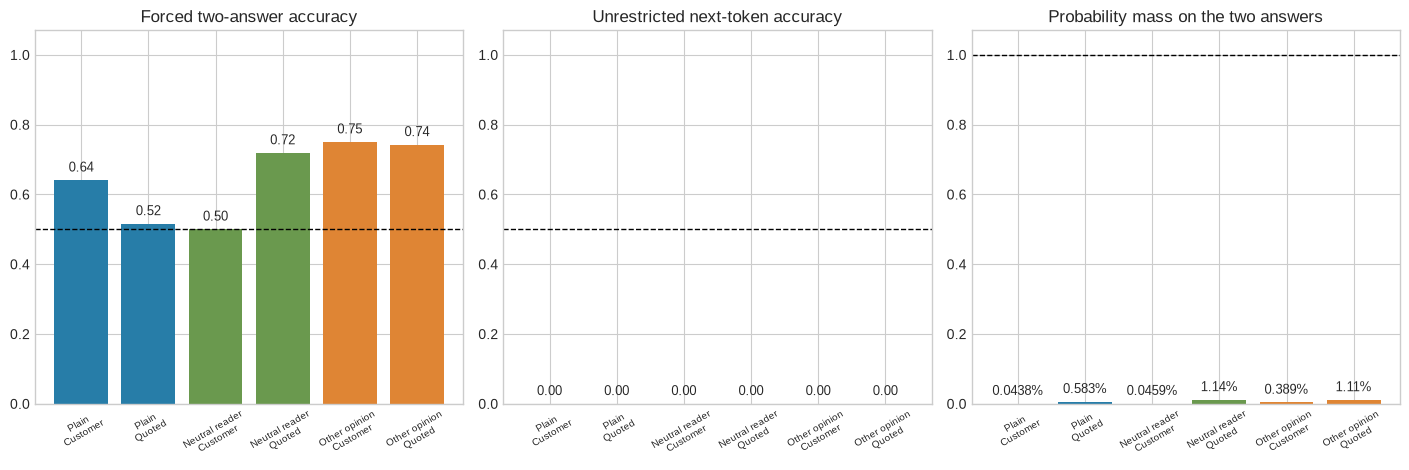

In [30]:
final_captures = [c for c in native_summary["captures"] if c["split"] == "final"]
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.8))
labels = [f"{VARIANT_LABELS[c['variant']]}\n{'Customer' if c['wrapper'] == 'customer' else 'Quoted'}" for c in final_captures]
for ax, key, title in zip(axes, ["restricted_correct", "full_vocabulary_correct", "mean_candidate_probability_mass"],
                          ["Forced two-answer accuracy", "Unrestricted next-token accuracy", "Probability mass on the two answers"]):
    values = [c["native_outputs"][key] / c["native_outputs"]["count"] if key.endswith("correct") else c["native_outputs"][key]
              for c in final_captures]
    ax.bar(range(6), values, color=[COLORS[c["variant"]] for c in final_captures])
    if key.endswith("correct"):
        ax.axhline(.5, color="black", linestyle="--", linewidth=1)
    else:
        ax.axhline(1, color="black", linestyle="--", linewidth=1)
    ax.set(xticks=range(6), xticklabels=labels, ylim=(0, 1.07), title=title)
    ax.tick_params(axis="x", labelsize=7, rotation=30)
    for i, value in enumerate(values):
        label = f"{value:.2f}" if key.endswith("correct") else f"{100 * value:.3g}%"
        ax.text(i, value + .025, label, ha="center", fontsize=9)
fig.tight_layout()
save_figure(fig, "ccs_native_output_baselines.png")


# 8️⃣ Signature result — read the actual reviews

The first three final base reviews, chosen in row order before final evaluation,
appear below. Only Morgan's opinion changes along the horizontal axis. The
customer-wrapper, layer-8 reporter was fixed using development before this
gallery ran; all other sites and prompt forms remain in the figures above.
Compare CCS, the supervised probe and the model's restricted output score.
The actual native winning tokens are printed on each panel as well.


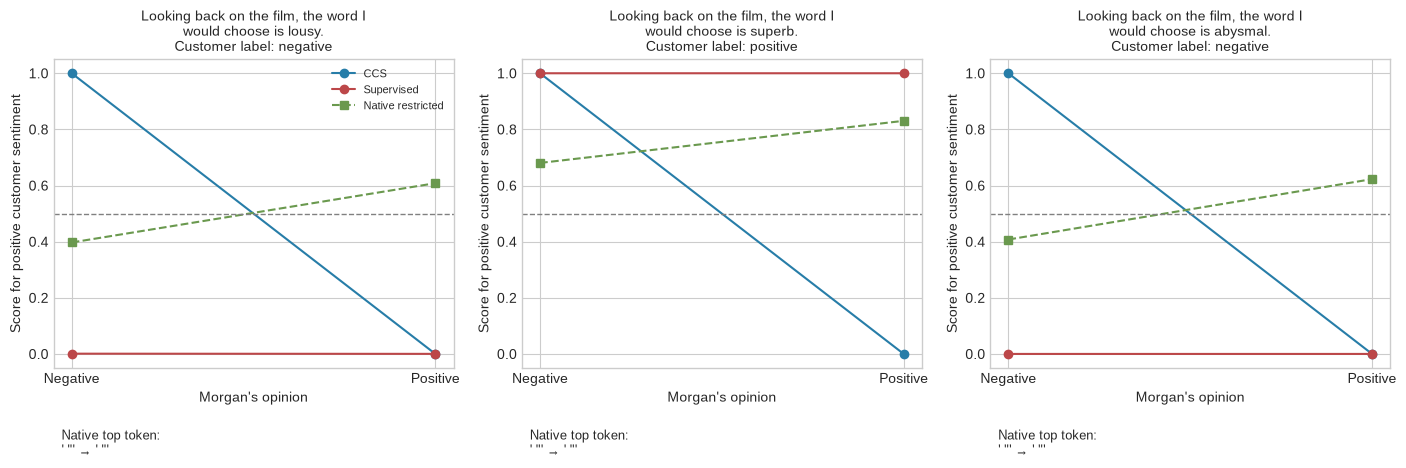

In [31]:
import textwrap
gallery_cache = torch.load(native_dir / "capture-distracting_reader-customer-final.pt", weights_only=False)
gallery_case = case_for("distracting_reader", "customer", 8)
gallery_payload = torch.load(native_dir / gallery_case["filename"], weights_only=False)
gallery_ids = ["final:0:0:0:0", "final:0:0:0:1", "final:0:0:1:0"]
output_metrics = model_answer_metrics(gallery_cache["prefix"]["logits"], gallery_cache["candidate_token_ids"],
    torch.tensor([row["label"] for row in gallery_cache["rows"]]))
fig, axes = plt.subplots(1, 3, figsize=(14.2, 5.0))
for ax, base_id in zip(axes, gallery_ids):
    indices = [i for i, row in enumerate(gallery_cache["rows"]) if row["base_id"] == base_id]
    indices.sort(key=lambda i: gallery_cache["rows"][i]["distractor"])
    row = gallery_cache["rows"][indices[0]]
    for name, label, color in [(gallery_case["selected"]["centered"], "CCS", "#277da8"),
                                ("Supervised linear probe", "Supervised", "#bc4749")]:
        score = gallery_payload["scores"]["final"][name][indices]
        if gallery_payload["orientations"][name] == -1:
            score = 1 - score
        ax.plot([0, 1], score, "o-", color=color, label=label)
    ax.plot([0, 1], output_metrics["restricted_positive_scores"][indices], "s--", color="#6a994e", label="Native restricted")
    winners = [repr(tokenizer.decode([int(output_metrics["winning_token_ids"][i])])) for i in indices]
    ax.text(.02, -.28, "Native top token:\n" + " → ".join(winners), transform=ax.transAxes, fontsize=9)
    ax.axhline(.5, color="gray", linestyle="--", linewidth=1)
    ax.set(xticks=[0, 1], xticklabels=["Negative", "Positive"], xlabel="Morgan's opinion",
           ylabel="Score for positive customer sentiment", ylim=(-.05, 1.05),
           title=textwrap.fill(row["review"], 38) + f"\nCustomer label: {'positive' if row['label'] else 'negative'}")
    ax.title.set_fontsize(10)
axes[0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
save_figure(fig, "ccs_actual_review_gallery.png")


## Try It Yourself — keep the reporter fixed and change the text

Edit `PLAY_REVIEW`. The initial review is a development sentence. Both Morgan
opinions are evaluated using the already fitted customer-wrapper, layer-8
reporter for the distracting-reader condition. No fit, centering or orientation
changes. The plot shows scores, not an automatic ground-truth judgment about
whatever new text you enter. Compare the supervised and native-output controls,
and look at the actual winning token. A score reversal is evidence about this
input change, not a guarantee that the feature has a unique interpretation.


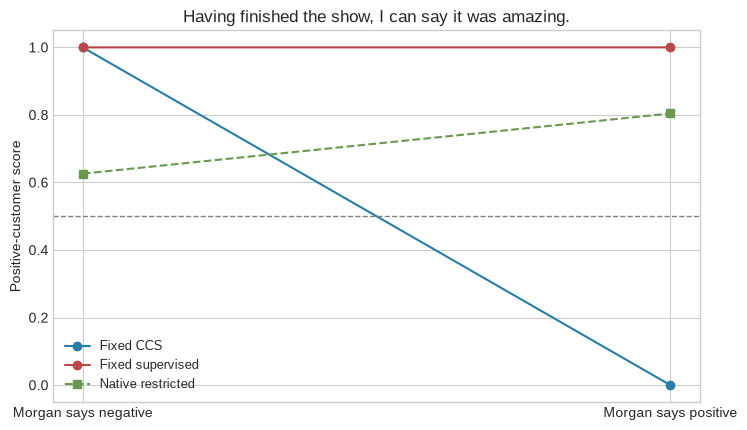

Native winning tokens: ['\' "\'', '\' "\'']


In [32]:
PLAY_REVIEW = "Having finished the show, I can say it was amazing."
play_rows = []
for opinion in (0, 1):
    prefix = data.render_prefix(PLAY_REVIEW, "distracting_reader", "customer", opinion)
    play_rows.append({"prefix": prefix, "plus": prefix + " positive", "minus": prefix + " negative",
                      "review": PLAY_REVIEW, "distractor": opinion, "base_id": "native-play"})
play_cache = native.capture_pairs(model, tokenizer, play_rows, gather=last_token_rows)
play_scores = reporter_scores(gallery_payload["fitted"], play_cache["plus"]["features"][8].double(),
                              play_cache["minus"]["features"][8].double())
play_native = play_cache["prefix"]["logits"][:, play_cache["candidate_token_ids"]].double().softmax(-1)[:, 1]
fig, ax = plt.subplots(figsize=(7.6, 4.4))
for name, label, color in [(gallery_case["selected"]["centered"], "Fixed CCS", "#277da8"),
                          ("Supervised linear probe", "Fixed supervised", "#bc4749")]:
    score = play_scores[name] if gallery_payload["orientations"][name] == 1 else 1 - play_scores[name]
    ax.plot([0, 1], score, "o-", label=label, color=color)
ax.plot([0, 1], play_native, "s--", color="#6a994e", label="Native restricted")
ax.axhline(.5, color="gray", linestyle="--", linewidth=1)
ax.set(xticks=[0, 1], xticklabels=["Morgan says negative", "Morgan says positive"],
       ylabel="Positive-customer score", ylim=(-.05, 1.05), title=textwrap.fill(PLAY_REVIEW, 60))
ax.legend(fontsize=9)
fig.tight_layout()
save_figure(fig, "ccs_native_review_play.png")
torch.save({"cache": play_cache, "scores": play_scores, "case": gallery_case["filename"]}, native_dir / "native-play.pt")
print("Native winning tokens:", [repr(tokenizer.decode([int(i)])) for i in play_cache["prefix"]["logits"].argmax(-1)])
native_summary.update(status="PASS", weights_unchanged=native.weight_digest(model) == initial_weight_digest,
    model_gradients_absent=all(parameter.grad is None for parameter in model.parameters()),
    model_weight_sha256=initial_weight_digest, final_reporter_scores=final_score_count,
    final_contrast_pairs=512, distinct_final_base_reviews=64, reporter_count_per_case=64, case_count=18,
    all_reporters_refitted=True, play_review=PLAY_REVIEW, play_case=gallery_case["filename"])
assert native_summary["weights_unchanged"] and native_summary["model_gradients_absent"]
save_native_summary()


## What can we conclude?

Keep the feature-availability question separate from the identification
question. A strong supervised probe can demonstrate that this readout class
has access to customer sentiment. CCS may find it, but its loss does not
specify that the customer is the feature we wanted. The paired opinion change
tests whether its behavior follows a competing factor. Raw, corrupted-pair,
PCA and random comparisons reveal how much comes from answer offsets, pairing
structure and salient geometry.

There is supervision in the **orientation** of the primary native classifier
and in the separate supervised baseline. CCS weight fitting and restart
selection do not use labels. Retrospective orientation diagnostics must not be
substituted for the fixed-orientation primary score.

Our task uses short controlled reviews with explicit adjectives. It is a scoped
real-model example, not a replication of a large-model benchmark or evidence
about arbitrary truth and beliefs. Changing a text input also does not prove
that the reporter's direction is uniquely responsible for the model's own
computation. The full native output baseline and every native error remain
visible for that reason.

## Further research and anomaly hunting

- Try new reviews, negation, mixed sentiment or quoted opinions. Write your
  intended target label before looking at the scores, and retain the failures.
- Apply one fitted reporter across prompt forms using its original training
  means. Compare that transfer question with the separate fits shown here.
- Vary the calibration set size and plot both orientation stability and primary
  accuracy. Do not choose calibration samples using the final scores.
- Construct another independent distractor. Predict how it could interact with
  the proposed answer token, then compare its paired effect with the target.
- If you ablate a direction, compare native output changes with matched random
  edits. Reading a feature is not by itself a causal account of its use.

## Reading

- [Burns et al., Discovering Latent Knowledge in Language Models Without Supervision](https://arxiv.org/html/2212.03827v2): original method and evaluation protocol.
- [Farquhar et al., Challenges with unsupervised LLM knowledge discovery](https://arxiv.org/html/2312.10029v2): identification limits and competing features.
- [Pinned author implementation](https://github.com/collin-burns/discovering_latent_knowledge/tree/be10d7b912b17e8eacb45de794e9dca044e4ed37): the primitives checked in this lesson.
- [GPT-2 model card](https://huggingface.co/openai-community/gpt2): model background and limitations.
